# Flood Radar Analytics, step by step

**Does a flood map learned on past floods still work on a new flood?**

This notebook is a guided tour of the whole project for someone who knows basic Python, numpy and pandas but
is new to machine learning and to satellite images. You will open the raw data, build every model input,
run the simple methods and the LightGBM model yourself, learn how the maps are scored, and then read the
full results of the project and the analyses that explain them.

## How to use this notebook

**Prerequisites**

- Python basics, numpy arrays and pandas DataFrames. Nothing else is assumed: every machine-learning or
  remote-sensing word is explained the first time it appears (in **bold**).
- The project's virtual environment (`.venv`, see the README) and its Jupyter kernel, *Python 3 (ipykernel)* (the start files in START_HERE.md set it up). Pick that kernel in Jupyter or VS Code.
- The data on disk under `data/raw/sen1floods11/` (run `python scripts/download_data.py` once; about 2 GB).
- The full-run result files in `results/` (they are part of the repository).

**Run order.** Run the cells from top to bottom (in Jupyter: *Kernel → Restart & Run All*). Later cells use
variables made by earlier ones. Keep the code in `src/flood_radar_analytics/` open next to the notebook: every
step calls a function from there, and the text tells you which file and function to read.

**Runtime.** About 3 to 4 minutes on an Apple-silicon Mac (M4). The slowest cells are marked *(slow, about N s)*.

**This notebook writes nothing.** It reads the data and `results/`, keeps everything else in memory, and
never overwrites a project file.

**Why there are two notebooks (the macOS rule).** The project uses two machine-learning libraries:
**LightGBM** (for the pixel model) and **PyTorch** (for the U-Net neural network). On macOS each of them
ships its own copy of a low-level library called OpenMP (it runs code on several CPU cores at once). If
both are loaded into the same Python process, the program crashes or freezes, depending on which one was
loaded first. The package docstring in `src/flood_radar_analytics/__init__.py` records this. So the project
never mixes them, and neither do the notebooks:

| Notebook | What it covers | Loads |
|---|---|---|
| `01_flood_radar_analytics.ipynb` (this one) | data, inputs, scoring, VV threshold, Otsu, LightGBM, the two kinds of test, the analyses | LightGBM, never PyTorch |
| `02_unet_walkthrough.ipynb` | the two U-Nets: what a U-Net is, its inputs, loss, training, inference | PyTorch, never LightGBM |

Read this one first. Notebook 02 assumes you know Parts 2 to 4 below.

## Contents

0. Setup
1. The question
2. The data
3. From chip to model input
4. Scoring a water map
5. Method 1: the VV threshold
6. Method 2: the authors' Otsu maps
7. Method 3: the LightGBM pixel model
8. Two kinds of test: the official split and leave-one-event-out
9. Why floods differ
10. Looking at the predictions
11. Recap, how to reproduce everything, and exercises

(Methods 4 and 5, the two U-Nets, are in notebook 02. Their *results* appear here too, read from `results/`.)

## 0. Setup

The project code lives in `src/flood_radar_analytics/`, which is not an installed package. We add `src/` to
Python's search path (`sys.path`) so that `import flood_radar_analytics` works, exactly as the scripts in
`scripts/` do. We also add `scripts/` because Part 8 reuses one helper from `scripts/cross_event.py`.

The last line is a safety check for the macOS rule: PyTorch must not be loaded in this notebook.

In [1]:
import json
import sys
import time
from pathlib import Path

NOTEBOOK_STARTED = time.time()

# The notebook lives in notebooks/; the project root is one level up.
ROOT = Path.cwd().parent if (Path.cwd().parent / "src").exists() else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT / "scripts"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from flood_radar_analytics import analysis, config, data, evaluation, pixel_model

pd.set_option("display.precision", 3)
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

RESULTS = config.RESULTS_DIR
print("project root:", ROOT)
print("data folder: ", config.SEN1FLOODS11_DIR, "exists:", config.SEN1FLOODS11_DIR.exists())
assert "torch" not in sys.modules, "PyTorch must not be loaded in this notebook (see 'How to use')"

project root: <project-root>
data folder:  <project-root>/data/raw/sen1floods11 exists: True


`pixel_model` does **not** import LightGBM at the top of the file: the import sits inside
`pixel_model.train`, so LightGBM is only loaded when we first train (Part 7). Look at the top of
`pixel_model.py` and `train()` to see this pattern; `unet.py` is the PyTorch side and we never import it here.

Two small helpers for pictures, used throughout. Radar images are drawn in grey (dark = low value), the
label in blue.

In [2]:
def show_vv(ax, chip, title="radar VV (dB)"):
    """Grey image of the VV band. NaN (no data) is drawn in red."""
    vv = np.ma.masked_invalid(chip.s1[0])
    cmap = plt.get_cmap("gray").copy()
    cmap.set_bad("red")
    ax.imshow(vv, cmap=cmap, vmin=-25, vmax=0)
    ax.set_title(title)
    ax.axis("off")


def show_mask(ax, mask, title, label=None):
    """Blue = water. If `label` is given, pixels with label -1 (no data) are grey."""
    img = np.where(mask, 1.0, 0.0)
    if label is not None:
        img = np.where(label == config.NODATA_LABEL, np.nan, img)
    cmap = plt.get_cmap("Blues").copy()
    cmap.set_bad("lightgrey")
    ax.imshow(img, cmap=cmap, vmin=0, vmax=1.3)
    ax.set_title(title)
    ax.axis("off")

## 1. The question

When a big flood hits, responders need a map of where the water is. Ordinary cameras in space
(**optical** satellites, such as Sentinel-2) cannot see through the storm clouds that come with floods.
A **radar** satellite (Sentinel-1) can: it sends its own microwave pulse and measures how much comes back
(the **backscatter**). Calm water acts like a mirror and bounces the pulse away, so **water looks dark** in
radar. Rough land scatters some of the pulse back and looks brighter.

The task is **image segmentation**: give every pixel of an image a class, here *water* or *not water*.
Each of the five methods is a function that takes one image (a **chip**) and returns a True/False array of
the same size (True = water). In the code this is the type `evaluation.Predictor`
(`Callable[[Chip], np.ndarray]`), which is why all five methods can be scored by the same code.

| # | Method | Learns from labels? | Looks at | Where |
|---|---|---|---|---|
| 1 | VV threshold | yes, one number | one radar value per pixel | `evaluation.fit_threshold`, `threshold_predictor` |
| 2 | Authors' Otsu | no | the dataset authors' per-scene threshold maps | `evaluation.authors_otsu_predictor` |
| 3 | LightGBM (radar + texture) | yes | a pixel and its neighbourhood statistics | `pixel_model.py` |
| 4 | U-Net (radar) | yes | whole image areas, radar only | `unet.py` (notebook 02) |
| 5 | U-Net (radar + optical) | yes | whole image areas, radar and optical | `unet.py` (notebook 02) |

A method that **learns** has a **training** step: it is shown examples where the right answer (the
**label**) is known, and adjusts itself. It is then **tested** on other examples. The project's real
question is about *which* examples it is tested on:

- **Familiar floods.** The dataset's official split tests on chips from the same floods the method trained
  on (Part 8).
- **New floods.** Train on 10 floods, test on the 11th, and repeat for each flood (**leave-one-event-out**,
  Part 8). The next real flood is always a new one, so this is the honest test.

## 2. The data

The dataset is **Sen1Floods11** (Bonafilia et al., 2020), the hand-labelled part: 446 **chips**, each a
512 × 512-pixel square of about 5 km × 5 km (one pixel is about 10 m × 10 m), from 11 flood events.
`config.py` describes the layers in its docstring. Each layer is a folder of GeoTIFF files (`.tif`, an image
format that can store several bands of numbers per pixel plus map coordinates):

| Folder | What | Values |
|---|---|---|
| `S1Hand` | Sentinel-1 radar, 2 bands: VV and VH | backscatter in dB (float); NaN = no data |
| `S2Hand` | Sentinel-2 optical, 13 bands | reflectance × 10,000 (integers) |
| `LabelHand` | the hand label | −1 no data, 0 not water, 1 water |
| `JRCWaterHand` | permanent water (JRC Global Surface Water) | 1 = water in normal times (rivers, lakes) |
| `S1OtsuLabelHand` | the dataset authors' own Otsu water map | 1 = water |

### 2.1 Files on disk

In [3]:
for layer in config.LAYERS:
    files = sorted((config.SEN1FLOODS11_DIR / layer).glob("*.tif"))
    print(f"{layer:<16} {len(files):>4} files, e.g. {files[0].name}")
print("splits:", sorted(p.name for p in config.SPLITS_DIR.glob("*.csv")))

S1Hand            446 files, e.g. Bolivia_103757_S1Hand.tif
S2Hand            446 files, e.g. Bolivia_103757_S2Hand.tif
LabelHand         446 files, e.g. Bolivia_103757_LabelHand.tif
JRCWaterHand      446 files, e.g. Bolivia_103757_JRCWaterHand.tif
S1OtsuLabelHand   446 files, e.g. Bolivia_103757_S1OtsuLabelHand.tif
splits: ['flood_bolivia_data.csv', 'flood_test_data.csv', 'flood_train_data.csv', 'flood_valid_data.csv']


The file names all follow `<Event>_<id>_<Layer>.tif`. The project names a chip by its radar file name
(`..._S1Hand.tif`) and gets the other layers by swapping the last part (see `data._layer_path`).
`data.event_of` reads the flood event from the name.

### 2.2 The official splits and the 11 events

The dataset ships four lists of chips, its **official split** (`config.SPLIT_FILES`, read by
`data.split_names`):

- **train**: chips for learning;
- **valid** (**validation**): chips for checking choices during training, such as when to stop;
- **test**: chips for the final score;
- **bolivia**: one whole flood that the official split keeps out of the other three.

`data.all_names()` is the union of the four lists: all 446 chips.

In [4]:
names = data.all_names()
split_of = {name: split for split in config.SPLIT_FILES for name in data.split_names(split)}
chips = pd.DataFrame({"name": names, "event": [data.event_of(n) for n in names],
                      "split": [split_of[n] for n in names]})
print(len(names), "chips;", data.event_of("Sri-Lanka_120804_S1Hand.tif"), "<- data.event_of example")
pd.crosstab(chips["event"], chips["split"], margins=True).loc[config.EVENTS + ["All"],
                                                                 ["train", "valid", "test", "bolivia", "All"]]

446 chips; Sri-Lanka <- data.event_of example


split,train,valid,test,bolivia,All
event,,,,,
Bolivia,0,0,0,15,15
Ghana,31,11,11,0,53
India,40,14,14,0,68
Mekong,18,6,6,0,30
Nigeria,10,4,4,0,18
Pakistan,16,6,6,0,28
Paraguay,39,14,14,0,67
Somalia,15,5,6,0,26
Spain,18,6,6,0,30


**What to notice**

- train, valid and test are drawn from the **same 10 floods**. A test chip often sits a few kilometres
  from a training chip of the same flood, imaged on the same day. That makes the official test a test on
  *familiar* floods.
- Bolivia appears only in its own list. It is the only flood the official split never trains on.
- The floods have very different numbers of chips (15 for Bolivia, 69 for the USA).

### 2.3 Load one chip

`data.load_chip(name, with_s2=False)` reads the layers of one chip into a `data.Chip` (a small dataclass):

- `s1`: radar, shape (2, 512, 512): band 0 is VV, band 1 is VH;
- `label`: shape (512, 512), values −1 / 0 / 1;
- `permanent_water`: shape (512, 512), True/False;
- `s2`: optical, shape (13, 512, 512), only if `with_s2=True`; divided by 10,000 so values are 0 to 1.

It also does one important cleaning step: **wherever the radar has no value (NaN), the label is set to −1**,
because no radar method can classify a pixel without radar. (If a file is missing on disk, `load_chip`
downloads it from the public bucket first; with the data downloaded, it just reads.)

We use the same chip as the beginner's guide (`report/beginners_guide.qmd`): **India_900498**, a wide,
braided river in flood. It is in the official *test* split.

In [5]:
CHIP_NAME = "India_900498_S1Hand.tif"
chip = data.load_chip(CHIP_NAME, with_s2=True)
print("event:", chip.event)
for field in ("s1", "label", "permanent_water", "s2"):
    arr = getattr(chip, field)
    print(f"{field:<16} shape {str(arr.shape):<16} dtype {arr.dtype}")

event: India
s1               shape (2, 512, 512)    dtype float32
label            shape (512, 512)       dtype int8
permanent_water  shape (512, 512)       dtype bool
s2               shape (13, 512, 512)   dtype float32


### 2.4 Radar values are in decibels (dB)

Radar backscatter is a ratio of returned to sent power and spans many orders of magnitude, so it is stored
on a logarithmic scale, the **decibel**: `dB = 10 × log10(ratio)`. Every 10 dB lower means 10 times less
power came back. Values here are negative; **more negative means darker**. A difference of 3 dB is already a
factor of 2.

- **VV**: the pulse is sent and received with vertical polarisation (orientation of the wave).
- **VH**: sent vertical, received horizontal. VH is weaker overall, and reacts more to vegetation.

In [6]:
for db in (-5, -10, -15, -20):
    print(f"{db:>4} dB = {10 ** (db / 10):.4f} of the power sent")

vv, vh = chip.s1
print()
print(pd.DataFrame({"VV": pd.Series(vv.ravel()).describe(), "VH": pd.Series(vh.ravel()).describe()}).T)

  -5 dB = 0.3162 of the power sent
 -10 dB = 0.1000 of the power sent
 -15 dB = 0.0316 of the power sent
 -20 dB = 0.0100 of the power sent

       count    mean    std     min     25%     50%     75%    max
VV  262144.0 -13.395  5.952 -48.268 -18.308 -12.432  -8.284  2.056
VH  262144.0 -21.489  7.541 -53.739 -26.194 -20.928 -15.172 -5.648


### 2.5 The layers of one chip, side by side

The optical image is shown in **true colour**: the red, green and blue bands (Sentinel-2 bands B4, B3, B2;
`config.S2_BAND_INDEX` maps band names to positions in `chip.s2`), brightened so they are visible.

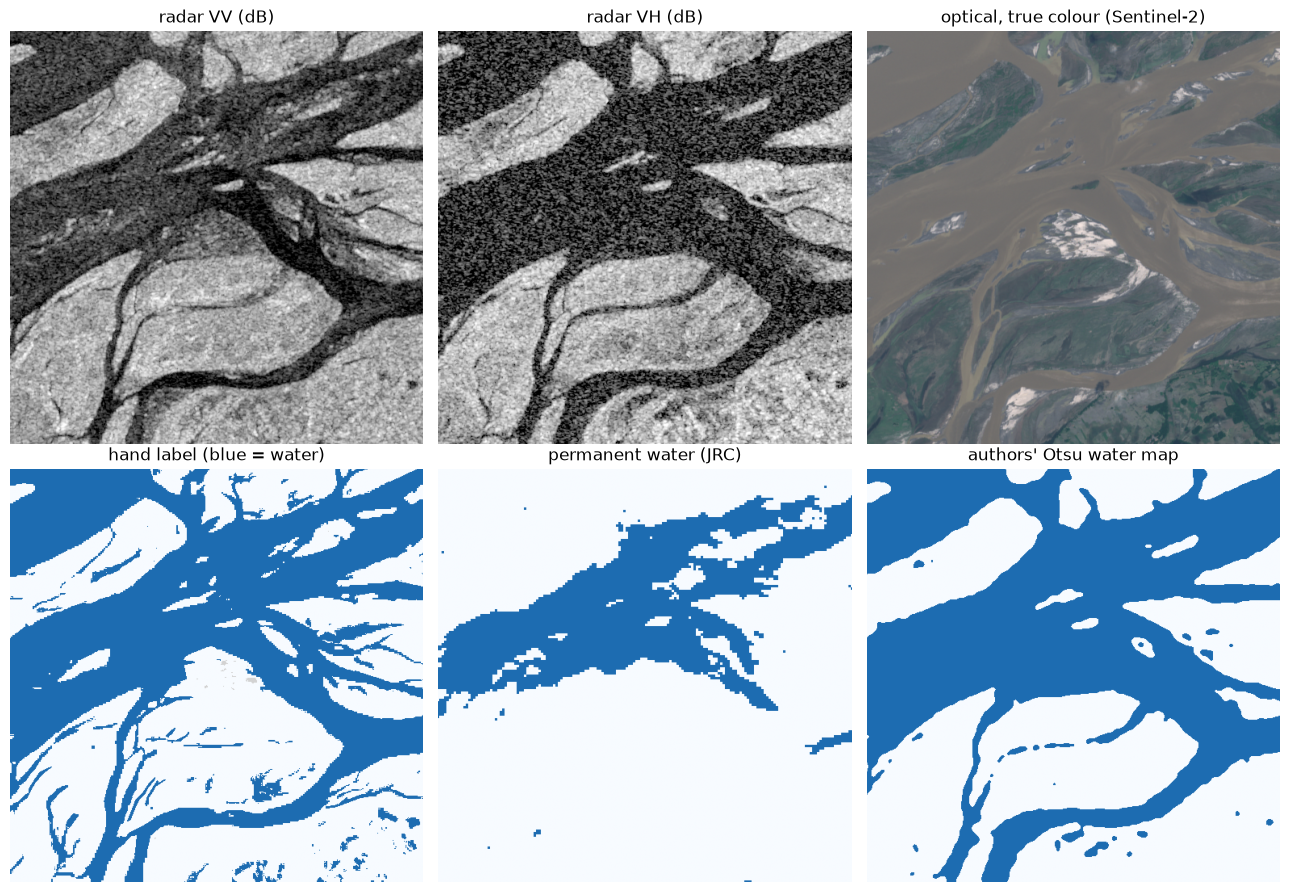

water share of labelled pixels: 47.3%
median VV, water: -18.4 dB   median VV, not water: -8.7 dB
share of the water that is permanent (JRC): 42.3%


In [7]:
idx = config.S2_BAND_INDEX
rgb = np.clip(np.stack([chip.s2[idx[b]] for b in ("B4", "B3", "B2")], axis=-1) / 0.3, 0, 1)
authors_otsu = evaluation.authors_otsu_predictor()(chip)

fig, axes = plt.subplots(2, 3, figsize=(13, 9))
show_vv(axes[0, 0], chip)
axes[0, 1].imshow(np.ma.masked_invalid(chip.s1[1]), cmap="gray", vmin=-32, vmax=-8)
axes[0, 1].set_title("radar VH (dB)"); axes[0, 1].axis("off")
axes[0, 2].imshow(rgb); axes[0, 2].set_title("optical, true colour (Sentinel-2)"); axes[0, 2].axis("off")
show_mask(axes[1, 0], chip.label == 1, "hand label (blue = water)", chip.label)
show_mask(axes[1, 1], chip.permanent_water, "permanent water (JRC)")
show_mask(axes[1, 2], authors_otsu, "authors' Otsu water map")
plt.tight_layout(); plt.show()

valid = chip.label != config.NODATA_LABEL
water = chip.label == 1
print(f"water share of labelled pixels: {water.sum() / valid.sum():.1%}")
print(f"median VV, water: {np.median(vv[water]):.1f} dB   median VV, not water: {np.median(vv[valid & ~water]):.1f} dB")
print(f"share of the water that is permanent (JRC): {(water & chip.permanent_water).sum() / water.sum():.1%}")

**What to notice**

- In the radar images the river and the flooded areas are dark, and the land is a grainy mid-grey.
  The graininess is **speckle**, a noise pattern every radar image has. It matters later (Part 3.4).
- The hand label (bottom left) is the answer key. Comparing it with the permanent-water map (bottom middle)
  separates **permanent water** (where the river normally runs) from **new floodwater** (everything else
  that is blue in the label). Part 9.4 uses this split.
- The authors' Otsu map (bottom right) is already one of the five methods: it is a file in the dataset.
- On this chip water is roughly 10 dB darker than land (see the medians printed above), so it is one of the
  easier chips.

### 2.6 Missing data: NaN in the radar, −1 in the label

Some pixels have no radar value (outside the satellite's swath or removed in processing) or were not
labelled. The chip USA_198411 has a lot of both. Red in the radar picture = NaN, grey in the label = −1.

pixels with no radar (NaN):  66.6%
pixels with label -1:        67.9%
every NaN-radar pixel has label -1: True
label values and counts: {np.int8(-1): np.int64(177922), np.int8(0): np.int64(75485), np.int8(1): np.int64(8737)}


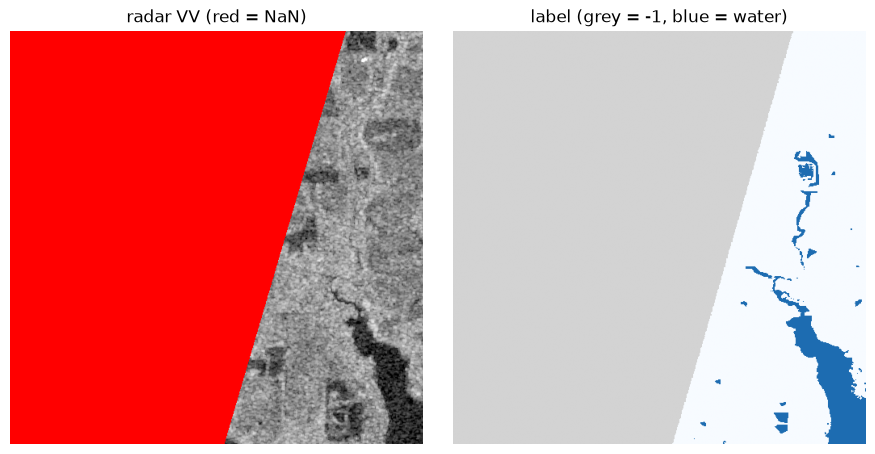

In [8]:
gappy = data.load_chip("USA_198411_S1Hand.tif")
no_radar = ~np.isfinite(gappy.s1).all(axis=0)
print(f"pixels with no radar (NaN):  {no_radar.mean():.1%}")
print(f"pixels with label -1:        {(gappy.label == -1).mean():.1%}")
print(f"every NaN-radar pixel has label -1: {bool((gappy.label[no_radar] == -1).all())}")
print("label values and counts:", dict(zip(*np.unique(gappy.label, return_counts=True))))

fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
show_vv(axes[0], gappy, "radar VV (red = NaN)")
show_mask(axes[1], gappy.label == 1, "label (grey = -1, blue = water)", gappy.label)
plt.tight_layout(); plt.show()

**What to notice:** `load_chip` turned every NaN-radar pixel into label −1. Every score in the project
ignores label −1 pixels (Part 4.3), so a method is never rewarded or punished for pixels nobody can check.

### 2.7 A chip is a grid of numbers: six pixels as a table

These are the same six pixels as the table in the beginner's guide. **NDWI** (normalised difference water
index) is a standard optical water index, `(green − NIR) / (green + NIR)` (NIR = near-infrared), computed by
`data.ndwi`; above 0 usually means water, because water absorbs near-infrared light.

In [9]:
PIXELS = [(177, 87), (263, 395), (356, 419), (104, 328), (19, 16), (455, 232)]
ndwi = data.ndwi(chip.s2)
LABEL_TEXT = {-1: "no data", 0: "not water", 1: "water"}
pixel_table = pd.DataFrame([{
    "row, col": f"({r}, {c})",
    "VV (dB)": vv[r, c], "VH (dB)": vh[r, c], "NDWI": ndwi[r, c],
    "hand label": LABEL_TEXT[int(chip.label[r, c])],
    "permanent water": bool(chip.permanent_water[r, c]),
    "authors' Otsu": "water" if authors_otsu[r, c] else "not water",
} for r, c in PIXELS]).set_index("row, col")
pixel_table

,VV (dB),VH (dB),NDWI,hand label,permanent water,authors' Otsu
"row, col",,,,,,
"(177, 87)",-22.299,-25.012,0.176,water,True,water
"(263, 395)",-15.536,-35.442,0.217,water,False,water
"(356, 419)",-16.985,-37.104,0.152,water,False,water
"(104, 328)",-13.184,-23.702,0.132,not water,False,water
"(19, 16)",-5.415,-15.115,-0.369,not water,False,not water
"(455, 232)",-7.922,-18.980,-0.055,not water,False,not water


**What to notice:** water pixels have low VV, but not all equally low: (263, 395) is water at about
−15.5 dB, brighter than the water at (177, 87). Keep that pixel in mind; it is the kind a single
cut-off misses (Parts 5 and 10).

### 2.8 Water is rare

Over the whole training split, how many labelled pixels are water? We loop over the 252 training chips once.
While we are at it, we keep a random sample of VV values with their labels; Part 5 uses it to draw a
histogram. *(slow, about 10 s: reads 252 chips)*

In [10]:
train_names = data.split_names("train")
rng = np.random.default_rng(config.RANDOM_SEED)
counts = {"water": 0, "not water": 0, "no data": 0}
sample_vv, sample_water = [], []
for name in train_names:
    c = data.load_chip(name)
    counts["water"] += int((c.label == 1).sum())
    counts["not water"] += int((c.label == 0).sum())
    counts["no data"] += int((c.label == -1).sum())
    valid_idx = np.flatnonzero(c.label.ravel() != config.NODATA_LABEL)
    take = rng.choice(valid_idx, size=min(2000, len(valid_idx)), replace=False) if len(valid_idx) else valid_idx
    sample_vv.append(c.s1[0].ravel()[take])
    sample_water.append(c.label.ravel()[take] == 1)
sample_vv, sample_water = np.concatenate(sample_vv), np.concatenate(sample_water)

labelled = counts["water"] + counts["not water"]
print(f"labelled training pixels: {labelled:,}")
print(f"water share: {counts['water'] / labelled:.1%}   (config.TRAIN_WATER_SHARE = {config.TRAIN_WATER_SHARE})")
print(f"VV sample for Part 5: {len(sample_vv):,} pixels")

labelled training pixels: 57,279,257
water share: 9.5%   (config.TRAIN_WATER_SHARE = 0.095)
VV sample for Part 5: 501,892 pixels


**What to notice:** only about 1 labelled pixel in 10 is water. That will matter twice: a lazy method that
says "no water anywhere" looks accurate (Part 4.2), and the U-Net's loss needs a part that focuses on water
(notebook 02).

## 3. From chip to model input

Models need numbers in a consistent form. This project has exactly **one** place where raw bands become
model inputs, `data.raw_channels` and `data.model_input` (and, for LightGBM, `pixel_model.pixel_features`).
Training, testing and the app all call these same functions, so the data can never be prepared in slightly
different ways in different places.

### 3.1 Clipping, the VH − VV channel, and normalisation

`data.raw_channels(chip, "s1")` returns three channels:

1. **VV clipped** to −30…5 dB and 2. **VH clipped** to −40…−5 dB (`config.DB_CLIP`). **Clipping** caps
   extreme values (a few very bright buildings, a few pixels at the noise floor) so they cannot dominate.
3. **VH − VV** (in dB this is the log of the ratio VH/VV, so the code calls it `ratio`). It describes *how*
   the surface scatters, independently of overall brightness, and helps separate water, vegetation and
   buildings.

`data.model_input(chip, variant)` then **normalises** each channel: subtract a mean and divide by a standard
deviation, so every channel is centred on 0 with a spread of about 1 (a **z-score**). Neural networks learn
much better when inputs are on similar scales. The means and standard deviations (`config.S1_MEAN`,
`config.S1_STD`) were computed once from the labelled pixels of the **training** split only. Using test
chips for this would leak information about the test into training. Finally, any remaining NaN becomes 0,
which after normalisation means "the training average": a neutral value.

In [11]:
raw = data.raw_channels(chip, "s1")
x = data.model_input(chip, "s1")
print("channels:", config.INPUT_CHANNELS["s1"])
print("S1_MEAN:", config.S1_MEAN, " S1_STD:", config.S1_STD)
print()
summary = pd.DataFrame({
    "raw min": raw.reshape(3, -1).min(axis=1), "raw max": raw.reshape(3, -1).max(axis=1),
    "raw mean": raw.reshape(3, -1).mean(axis=1),
    "input mean": x.reshape(3, -1).mean(axis=1), "input std": x.reshape(3, -1).std(axis=1),
}, index=config.INPUT_CHANNELS["s1"])
summary

channels: ['vv', 'vh', 'ratio']
S1_MEAN: [-10.45 -17.3   -6.85]  S1_STD: [4.04 4.69 3.39]



,raw min,raw max,raw mean,input mean,input std
vv,-30.000,2.056,-13.383,-0.726,1.463
vh,-40.000,-5.648,-21.370,-0.868,1.532
ratio,-33.946,11.002,-7.986,-0.335,1.399


A by-hand check of the normalisation for one pixel, the water pixel at (177, 87):

In [12]:
r, c = 177, 87
by_hand = (raw[:, r, c] - config.S1_MEAN) / config.S1_STD
print("raw dB values     :", raw[:, r, c].round(2))
print("(raw - mean) / std:", by_hand.round(3))
print("model_input       :", x[:, r, c].round(3))

raw dB values     : [-22.3  -25.01  -2.71]
(raw - mean) / std: [-2.933 -1.644  1.22 ]
model_input       : [-2.933 -1.644  1.22 ]


**What to notice:** the normalised values for this chip are not centred exactly on 0. That is expected:
the constants come from the whole training split, and this chip has much more water (dark pixels) than
average. A dark water pixel ends up around −2 to −3 in VV: "two to three standard deviations darker than a
typical training pixel".

### 3.2 The radar + optical variant (`"s1s2"`)

`config.INPUT_CHANNELS` lists the two input variants. The U-Net (radar + optical) uses 10 channels: the 3
radar channels, 6 optical bands clipped to 0…1 (blue B2, green B3, red B4, near-infrared B8, two short-wave
infrared bands B11 and B12, where water is very dark), and NDWI. Each has its own mean and standard
deviation (`config.S2_MEAN`, `config.S2_STD`). Notebook 02 uses these inputs; here we just look at them.

s1s2 channels: ['vv', 'vh', 'ratio', 'B2', 'B3', 'B4', 'B8', 'B11', 'B12', 'ndwi']
shape: (10, 512, 512)


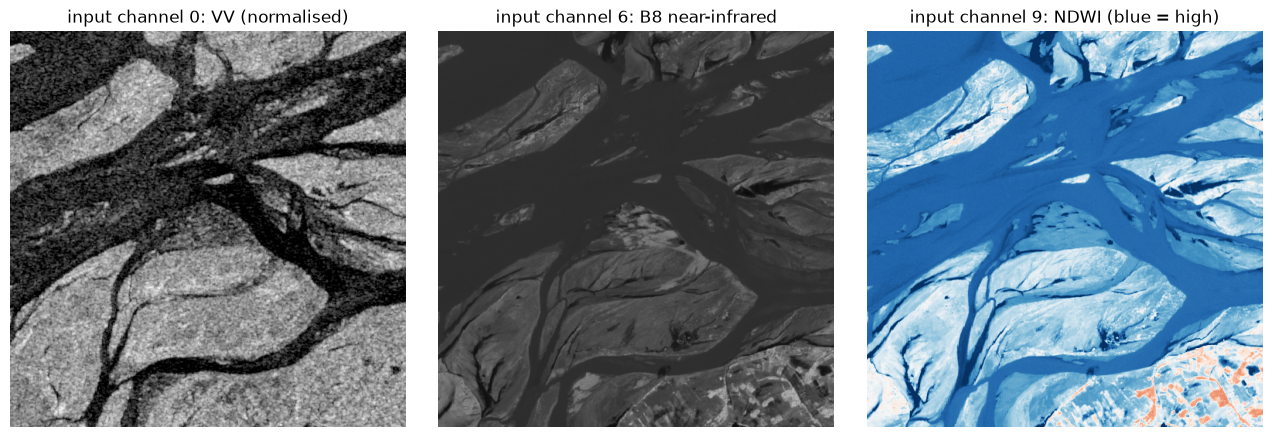

In [13]:
x10 = data.model_input(chip, "s1s2")
print("s1s2 channels:", config.INPUT_CHANNELS["s1s2"])
print("shape:", x10.shape)

fig, axes = plt.subplots(1, 3, figsize=(13, 4.3))
axes[0].imshow(x10[0], cmap="gray", vmin=-3, vmax=3); axes[0].set_title("input channel 0: VV (normalised)")
axes[1].imshow(x10[6], cmap="gray", vmin=-3, vmax=3); axes[1].set_title("input channel 6: B8 near-infrared")
axes[2].imshow(x10[9], cmap="RdBu", vmin=-3, vmax=3); axes[2].set_title("input channel 9: NDWI (blue = high)")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

**What to notice:** water is dark in near-infrared and stands out in NDWI, which is why optical data helps
so much when the sky is clear. Optical images of floods are often partly cloudy, though; clouds are bright
in every optical band and hide the ground.

### 3.3 Features for LightGBM: one table row per pixel

LightGBM does not see images. It sees a **table**: one row per pixel, one column per **feature** (a number
describing that pixel). `pixel_model.pixel_features(chip)` builds that table: 512 × 512 = 262,144 rows,
in row-major order (row 0 left to right, then row 1, ...), so pixel (r, c) is row `r * 512 + c`.

Columns: `vv`, `vh`, `ratio` (clipped as in 3.1, but **not** normalised: tree models do not care about
scale), plus for both VV and VH the neighbourhood **mean** and **standard deviation** in square windows of
5 and 15 pixels (`pixel_model.WINDOWS`; about 50 m and 150 m across).

In [14]:
features = pixel_model.pixel_features(chip)
print("table shape:", features.shape, " windows:", pixel_model.WINDOWS)
features.iloc[[r * config.CHIP_SIZE + c for r, c in PIXELS]].set_index(pixel_table.index)

table shape: (262144, 11)  windows: (5, 15)


,vv,vh,ratio,vv_mean_5,vv_std_5,vv_mean_15,vv_std_15,vh_mean_5,vh_std_5,vh_mean_15,vh_std_15
"row, col",,,,,,,,,,,
"(177, 87)",-22.299,-25.012,-2.713,-21.283,1.941,-18.727,3.165,-28.992,5.131,-28.739,5.012
"(263, 395)",-15.536,-35.442,-19.906,-16.610,3.612,-15.810,3.715,-26.819,4.088,-26.193,4.169
"(356, 419)",-16.985,-37.104,-20.119,-17.211,2.181,-17.453,2.770,-33.739,4.874,-28.512,4.829
"(104, 328)",-13.184,-23.702,-10.518,-13.795,1.784,-14.615,3.174,-24.024,3.590,-26.710,6.016
"(19, 16)",-5.415,-15.115,-9.700,-7.875,2.560,-12.065,6.527,-15.187,2.292,-17.694,6.280
"(455, 232)",-7.922,-18.980,-11.058,-7.763,0.705,-8.754,2.498,-16.734,1.524,-17.081,4.063


### 3.4 Why neighbourhood statistics: speckle

Radar **speckle** makes even a uniform field look grainy: neighbouring pixels of the same surface can
differ by several dB. One pixel's value is therefore noisy. Two simple neighbourhood statistics help:

- the **local mean** (average of the window) smooths speckle away and says "is this *area* dark?";
- the **local standard deviation** says "is this area smooth or grainy?". The usual intuition (it is in
  the docstring of `pixel_model.py` and in the beginner's guide) is that calm water is smooth and land is
  grainy. We will check that against the data rather than take it on trust.

`pixel_model._local_stats` computes both with `scipy.ndimage.uniform_filter` (a moving-window average),
using `std = sqrt(mean(x²) − mean(x)²)`. NaN pixels are first filled with the chip's mean, so one missing
pixel cannot spoil its neighbours. A by-hand check for one interior pixel:

In [15]:
r, c = 263, 395
window = np.clip(vv, *config.DB_CLIP["vv"])[r - 2:r + 3, c - 2:c + 3]   # the 5 x 5 window around (r, c)
row = features.iloc[r * config.CHIP_SIZE + c]
print(f"by hand: mean {window.mean():.3f}  std {window.std():.3f}")
print(f"feature: mean {row['vv_mean_5']:.3f}  std {row['vv_std_5']:.3f}")

by hand: mean -16.610  std 3.612
feature: mean -16.610  std 3.612


Now the whole chip: raw VV, the 15-pixel local mean, the 5-pixel local standard deviation, and a histogram of
that standard deviation for water and for land pixels of this chip. `grid` turns a feature column back into a
512 × 512 image.

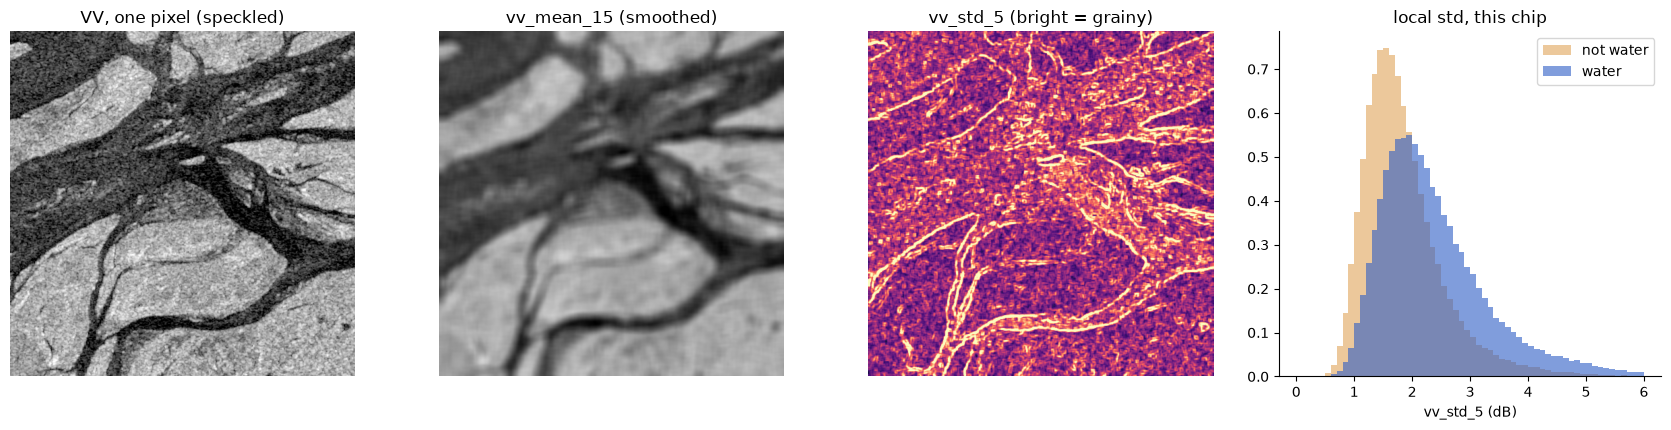

median vv_std_5: water 2.19 dB, not water 1.71 dB


In [16]:
grid = lambda col: features[col].to_numpy().reshape(chip.label.shape)
fig, axes = plt.subplots(1, 4, figsize=(17, 4.4))
show_vv(axes[0], chip, "VV, one pixel (speckled)")
axes[1].imshow(grid("vv_mean_15"), cmap="gray", vmin=-25, vmax=0); axes[1].set_title("vv_mean_15 (smoothed)")
axes[2].imshow(grid("vv_std_5"), cmap="magma", vmin=0, vmax=4); axes[2].set_title("vv_std_5 (bright = grainy)")
for ax in axes[:3]: ax.axis("off")
std5 = grid("vv_std_5")
axes[3].hist([std5[water], std5[valid & ~water]], bins=60, range=(0, 6), density=True,
             label=["water", "not water"], color=["#2c5cc5", "#e0a458"], histtype="stepfilled", alpha=0.6)
axes[3].set_xlabel("vv_std_5 (dB)"); axes[3].set_title("local std, this chip"); axes[3].legend()
plt.tight_layout(); plt.show()
print(f"median vv_std_5: water {np.median(std5[water]):.2f} dB, not water {np.median(std5[valid & ~water]):.2f} dB")

**What to notice**

- The smoothed image (`vv_mean_15`) shows the water bodies much more cleanly than the raw VV: averaging
  over a neighbourhood removes most of the speckle. This is the main gain from neighbourhood features.
- The local standard deviation does **not** follow the "water is smooth" intuition on this chip: its
  median is *higher* on water than on land (printed above). Two reasons: in decibels, very dark water near
  the sensor's noise floor is itself noisy, and windows on narrow, braided channels straddle the shoreline,
  mixing dark water with bright land. Part 7.2 checks this over the whole training sample.
- The lesson for a beginner: a feature can still be useful when the textbook story about it is wrong,
  because a learned model uses whatever pattern is really in the data. (The windows here are fixed by hand;
  the U-Net in notebook 02 *learns* which neighbourhood patterns matter.)

## 4. Scoring a water map

Before building methods, we need to know how to grade them. All scoring is in `evaluation.py`.

### 4.1 The confusion counts, by hand on a 4 × 4 example

Compare a prediction with the label pixel by pixel. Each pixel falls in one of four boxes:

| | label: water | label: not water |
|---|---|---|
| **predicted water** | **TP** true positive (found water) | **FP** false positive (false alarm) |
| **predicted not water** | **FN** false negative (missed water) | **TN** true negative |

From the four counts:

- **IoU** (intersection over union) = TP / (TP + FP + FN): the overlap of predicted and real water divided by
  the area covered by either. 1 = perfect, 0 = no overlap. **This is the project's main score.**
- **precision** = TP / (TP + FP): of what was called water, the share that really is water.
- **recall** = TP / (TP + FN): of the real water, the share that was found.
- **F1** = 2·TP / (2·TP + FP + FN): a balance of precision and recall.
- **accuracy** = (TP + TN) / all: share of pixels right. (Not used by the project; see 4.2 for why.)

In [17]:
label_4x4 = np.array([[1, 1, 0, 0],
                      [1, 1, 0, 0],
                      [0, 0, 0, 0],
                      [0, 0, 0, 1]])
pred_4x4 = np.array([[1, 1, 1, 0],
                     [1, 0, 0, 0],
                     [0, 0, 0, 0],
                     [0, 0, 0, 0]], dtype=bool)
t = label_4x4 == 1
tp, fp = int((pred_4x4 & t).sum()), int((pred_4x4 & ~t).sum())
fn, tn = int((~pred_4x4 & t).sum()), int((~pred_4x4 & ~t).sum())
print(f"by hand: TP={tp} FP={fp} FN={fn} TN={tn}")
print(f"         IoU={tp / (tp + fp + fn):.3f}  precision={tp / (tp + fp):.3f}  recall={tp / (tp + fn):.3f}"
      f"  accuracy={(tp + tn) / 16:.3f}")

conf = evaluation.Confusion().add(pred_4x4, label_4x4)
print("Confusion:", {k: round(v, 3) for k, v in conf.as_dict().items()})

by hand: TP=3 FP=1 FN=2 TN=10
         IoU=0.500  precision=0.750  recall=0.600  accuracy=0.812
Confusion: {'IoU': 0.5, 'F1': 0.667, 'precision': 0.75, 'recall': 0.6, 'tp': 3, 'fp': 1, 'fn': 2, 'tn': 10}


**What to notice:** `evaluation.Confusion` gives the same numbers as the hand count. Accuracy is high
(13 of 16 pixels right) while IoU is only 0.5: accuracy is flattered by the many easy "not water" pixels.

### 4.2 The "say no water everywhere" trap

Take the official **test** split. A useless method that answers "not water" for every pixel has TP = 0 and
FP = 0. Its counts follow from the label alone. We read the label totals from the full run's
`results/benchmark.json` (any method's TP + FN is the number of water pixels; TN + FP is the rest), and
compare with the VV threshold method's real counts on the same pixels.

In [18]:
bench = json.loads((RESULTS / "benchmark.json").read_text())
vv_test = bench["splits"]["test"]["VV threshold"]["pooled"]
n_water = vv_test["tp"] + vv_test["fn"]
n_land = vv_test["tn"] + vv_test["fp"]
print(f"test split: {n_water:,} water pixels, {n_land:,} not-water pixels ({n_water / (n_water + n_land):.1%} water)")

lazy = evaluation.Confusion(tp=0, fp=0, fn=n_water, tn=n_land)
real = evaluation.Confusion(**{k: vv_test[k] for k in ("tp", "fp", "fn", "tn")})
accuracy = lambda c: (c.tp + c.tn) / (c.tp + c.fp + c.fn + c.tn)
pd.DataFrame({"accuracy": [accuracy(lazy), accuracy(real)], "IoU": [lazy.iou, real.iou],
              "recall": [lazy.recall, real.recall]}, index=["'no water anywhere'", "VV threshold"])

test split: 2,515,008 water pixels, 17,928,951 not-water pixels (12.3% water)


,accuracy,IoU,recall
'no water anywhere',0.877,0.000,0.000
VV threshold,0.924,0.464,0.538


**What to notice:** "no water anywhere" scores about 88% accuracy and IoU 0, and the real (if simple)
method's accuracy is only a few points higher. Accuracy cannot tell a useless map from a useful one when
water is rare; IoU can. That is why the project (like the Sen1Floods11 paper) reports water IoU.

### 4.3 Label −1 is ignored

`Confusion.add(predicted, label)` keeps only pixels whose label is not −1 (`config.NODATA_LABEL`), so
whatever a method says there does not count:

In [19]:
label_with_gap = np.array([1, -1, 0, 1])
predicted = np.array([True, True, False, True])
c = evaluation.Confusion().add(predicted, label_with_gap)
print(c.as_dict())   # 3 pixels counted, the -1 pixel is skipped

{'IoU': 1.0, 'F1': 1.0, 'precision': 1.0, 'recall': 1.0, 'tp': 2, 'fp': 0, 'fn': 0, 'tn': 1}


### 4.4 Pooling: one IoU for many chips

To score a set of chips, the project **pools**: it adds up TP, FP and FN over all chips and computes one IoU
from the totals (`Confusion.add` accumulates; `evaluation.Evaluation` keeps one pooled `Confusion` plus one per
event). It does *not* average per-chip IoUs. Why it matters, with two made-up chips:

In [20]:
big = evaluation.Confusion(tp=9000, fp=500, fn=500, tn=50_000)    # chip with lots of water, mapped well
small = evaluation.Confusion(tp=0, fp=50, fn=10, tn=60_000)       # chip with 10 water pixels, all missed
pooled = evaluation.Confusion(tp=big.tp + small.tp, fp=big.fp + small.fp, fn=big.fn + small.fn,
                              tn=big.tn + small.tn)
print(f"per-chip IoU: {big.iou:.3f} and {small.iou:.3f} -> mean {np.mean([big.iou, small.iou]):.3f}")
print(f"pooled IoU:   {pooled.iou:.3f}")

per-chip IoU: 0.900 and 0.000 -> mean 0.450
pooled IoU:   0.895


**What to notice:** averaging per chip lets a chip with 10 water pixels weigh as much as a chip with 9,500.
Pooling weighs every water pixel equally. Keep this in mind in Part 8: the "pooled" leave-one-event-out IoU
is pooled over all 446 chips, not an average of the 11 per-flood IoUs.

`evaluation.evaluate(predictors, names)` is the function that runs all of this: for each chip name it loads
the chip once, runs every predictor in the dictionary, and adds the result to that method's `Evaluation`.

## 5. Method 1: the VV threshold

The simplest radar water detector: **water wherever VV is below one cut-off** (a **threshold**, in dB).
It has one thing to learn: the cut-off.

### 5.1 How `evaluation.fit_threshold` picks the cut-off

It tries every candidate from −25 to −10.25 dB in steps of 0.25 dB and keeps the one with the best pooled IoU
on the training chips. Done naively that would be 60 passes over 57 million pixels, so it uses a trick:

1. collect VV and "is water" for every labelled training pixel, and **sort by VV**;
2. take the **cumulative sum** of "is water" along the sorted list: `cum_water[k-1]` is the number of water
   pixels among the `k` darkest pixels;
3. for a candidate `t`, `k = searchsorted(vv_sorted, t)` is the number of pixels with VV < t (all predicted
   water). Then TP = `cum_water[k-1]`, FP = k − TP, FN = total water − TP, so
   IoU = TP / (TP + FP + FN) = TP / (k + total_water − TP).

Read the function in `evaluation.py` with this list next to it. *(slow, about 15 s: reads 252 chips)*

In [21]:
t0 = time.time()
threshold = evaluation.fit_threshold(train_names)
print(f"learned threshold: water where VV < {threshold} dB   ({time.time() - t0:.0f} s)")
print(f"full run (results/benchmark.json): {bench['vv_threshold_db']} dB")

learned threshold: water where VV < -16.75 dB   (11 s)
full run (results/benchmark.json): -16.75 dB


### 5.2 Picture it: VV for water vs land

The histogram uses the random training sample from Part 2.8. The right panel recomputes the IoU of each
candidate threshold on that sample with the same cumulative-sum idea, to show the shape of the curve.

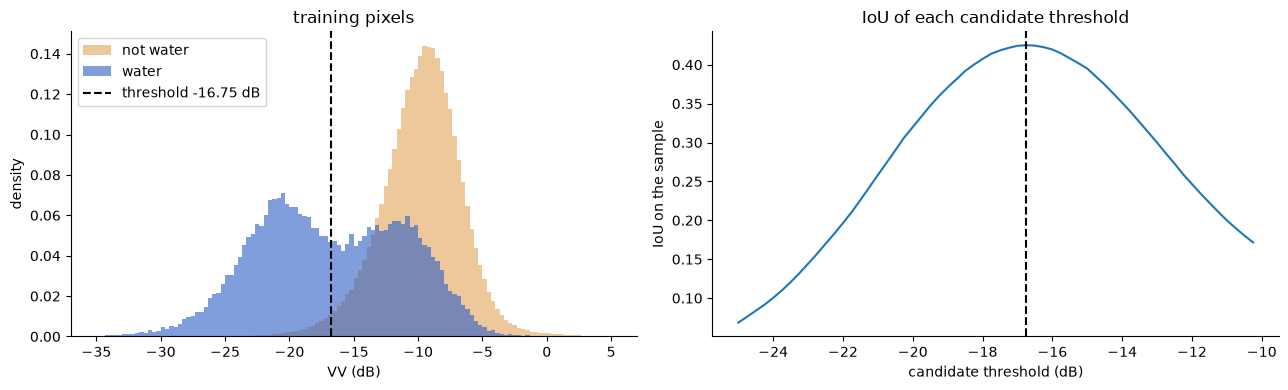

best candidate on the sample: -16.75 dB (IoU 0.425)


In [22]:
candidates = np.arange(-25.0, -10.0, 0.25)
order = np.argsort(sample_vv)
vv_sorted, cum = sample_vv[order], np.cumsum(sample_water[order])
k = np.searchsorted(vv_sorted, candidates)
tp_c = np.where(k > 0, cum[np.maximum(k - 1, 0)], 0)
iou_curve = tp_c / (k + sample_water.sum() - tp_c)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist([sample_vv[sample_water], sample_vv[~sample_water]], bins=120, range=(-35, 5), density=True,
             label=["water", "not water"], color=["#2c5cc5", "#e0a458"], histtype="stepfilled", alpha=0.6)
axes[0].axvline(threshold, color="k", ls="--", label=f"threshold {threshold} dB")
axes[0].set_xlabel("VV (dB)"); axes[0].set_ylabel("density"); axes[0].legend(); axes[0].set_title("training pixels")
axes[1].plot(candidates, iou_curve); axes[1].axvline(threshold, color="k", ls="--")
axes[1].set_xlabel("candidate threshold (dB)"); axes[1].set_ylabel("IoU on the sample")
axes[1].set_title("IoU of each candidate threshold")
plt.tight_layout(); plt.show()
print(f"best candidate on the sample: {candidates[iou_curve.argmax()]} dB (IoU {iou_curve.max():.3f})")

**What to notice:** the two histograms overlap a lot. Some water is brighter than −16.75 dB (missed: FN) and
some land is darker (false alarms: FP). No single cut-off can separate them, which caps what this method
can do. The **densities** are drawn so both shapes are visible; in raw counts the land histogram is about
nine times taller.

### 5.3 Use it on our chip

`evaluation.threshold_predictor(threshold)` returns a predictor: a function `chip -> water mask`
(`isfinite(VV) & VV < threshold`).

VV threshold on India_900498_S1Hand.tif: IoU 0.660  precision 0.950  recall 0.683


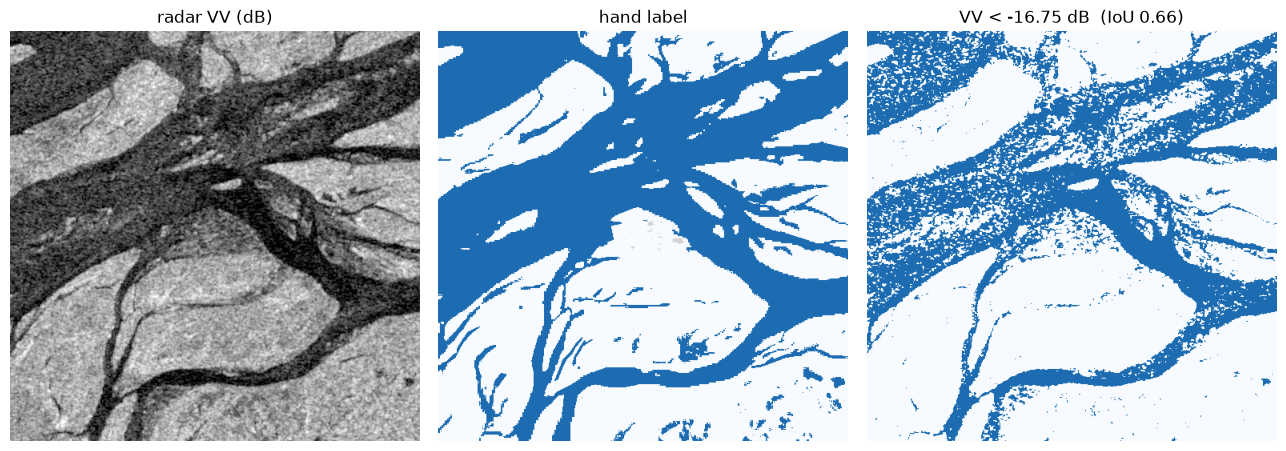

In [23]:
vv_predict = evaluation.threshold_predictor(threshold)
vv_mask = vv_predict(chip)
c = evaluation.Confusion().add(vv_mask, chip.label)
print(f"VV threshold on {CHIP_NAME}: IoU {c.iou:.3f}  precision {c.precision:.3f}  recall {c.recall:.3f}")

fig, axes = plt.subplots(1, 3, figsize=(13, 4.4))
show_vv(axes[0], chip)
show_mask(axes[1], chip.label == 1, "hand label", chip.label)
show_mask(axes[2], vv_mask, f"VV < {threshold} dB  (IoU {c.iou:.2f})")
plt.tight_layout(); plt.show()

**What to notice:** the threshold finds the main channels but turns parts of the river into scattered dots
(speckle pushes some water pixels above the cut-off) and misses the brighter floodwater: precision is high
(0.95, few false alarms) but recall is lower (0.68, a third of the water missed), giving IoU 0.66. This chip was
in the official *test* split, so this is a fair score for a familiar flood.

## 6. Method 2: the authors' Otsu maps

### 6.1 What Otsu's method does

**Otsu's method** (1979) picks a threshold for *one image* without any labels. It looks at the histogram
of values and tries every possible cut-off. Each cut-off splits the pixels into a dark group and a bright
group, and Otsu keeps the cut-off where the two groups are **as far apart as possible** relative to their
sizes: it maximises the *between-class variance*
`w_dark · w_bright · (mean_dark − mean_bright)²`, where `w` is the share of pixels in each group.

Its strength: it adapts to each scene, so if water is brighter than usual in one flood, the cut-off moves
with it. Its weakness: it *always* finds a split, even in an image with no water at all.

`evaluation.otsu_water(vv_db)` runs Otsu (from scikit-image) on the VV values of one array. Below we also
do it by hand with the formula above.

Otsu threshold for this chip: scikit-image -13.97 dB, by hand -13.84 dB


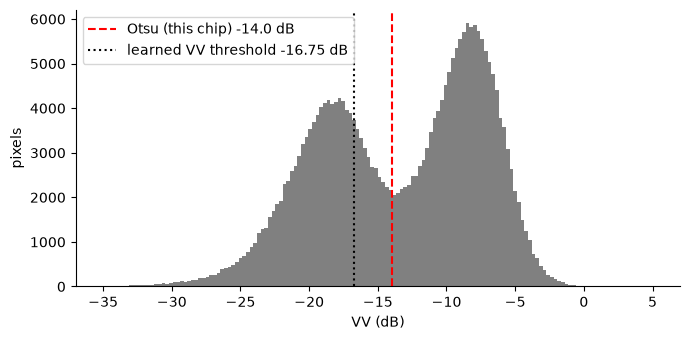

In [24]:
from skimage.filters import threshold_otsu

vv_valid = vv[np.isfinite(vv)]
otsu_t = threshold_otsu(vv_valid)

# By hand: between-class variance for a grid of cut-offs.
cuts = np.linspace(vv_valid.min(), vv_valid.max(), 400)[1:-1]
between = []
for t in cuts:
    dark, bright = vv_valid[vv_valid < t], vv_valid[vv_valid >= t]
    w_d, w_b = len(dark) / len(vv_valid), len(bright) / len(vv_valid)
    between.append(w_d * w_b * (dark.mean() - bright.mean()) ** 2)
by_hand_t = cuts[int(np.argmax(between))]
print(f"Otsu threshold for this chip: scikit-image {otsu_t:.2f} dB, by hand {by_hand_t:.2f} dB")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(vv_valid, bins=150, range=(-35, 5), color="grey")
ax.axvline(otsu_t, color="r", ls="--", label=f"Otsu (this chip) {otsu_t:.1f} dB")
ax.axvline(threshold, color="k", ls=":", label=f"learned VV threshold {threshold} dB")
ax.set_xlabel("VV (dB)"); ax.set_ylabel("pixels"); ax.legend(); plt.tight_layout(); plt.show()

**What to notice:** on this chip the histogram has two humps (water and land), and Otsu's cut-off
(about −14 dB) falls in the valley between them, about 3 dB brighter than the learned threshold. The library
and the by-hand search agree to within about 0.1 dB, the step of the by-hand grid.

### 6.2 Per-chip Otsu vs the authors' Otsu maps

The dataset authors ran Otsu on whole **scenes** (the large satellite image each chip was cut from) and
published the resulting water maps as the `S1OtsuLabelHand` layer. The project uses those maps *as
published* (`evaluation.authors_otsu_predictor` just reads the file); it does not re-fit anything. This
method has no training step.

Why not run Otsu per chip ourselves? A 5 km chip often has little or no water, and Otsu always finds a
split. Here is chip Ghana_156478, which has **no** labelled water at all:

In [25]:
otsu_predict = evaluation.authors_otsu_predictor()
for name in (CHIP_NAME, "Ghana_156478_S1Hand.tif"):
    c_chip = chip if name == CHIP_NAME else data.load_chip(name)
    per_chip = evaluation.otsu_water(c_chip.s1[0])
    published = otsu_predict(c_chip)
    ok = c_chip.label != config.NODATA_LABEL
    print(f"{name}: labelled water {np.mean(c_chip.label[ok] == 1):.1%} | "
          f"per-chip Otsu calls {per_chip[ok].mean():.1%} water (IoU {evaluation.Confusion().add(per_chip, c_chip.label).iou:.2f}) | "
          f"authors' map calls {published[ok].mean():.1%} water (IoU {evaluation.Confusion().add(published, c_chip.label).iou:.2f})")

India_900498_S1Hand.tif: labelled water 47.3% | per-chip Otsu calls 45.2% water (IoU 0.77) | authors' map calls 48.8% water (IoU 0.76)
Ghana_156478_S1Hand.tif: labelled water 0.0% | per-chip Otsu calls 45.6% water (IoU 0.00) | authors' map calls 0.0% water (IoU 0.00)


**What to notice**

- On the India chip, per-chip Otsu and the authors' scene-level map both do well (IoU about 0.77), better
  than the learned VV threshold (0.66), because they adapt to this scene.
- On the Ghana chip with no water, per-chip Otsu declares about 46% of the chip water: it must split the
  histogram somewhere. The authors' scene-level map, made from a whole scene that did contain water, calls
  none of this chip water, which is right.
- Both get IoU 0.00 on the Ghana chip, though only one is wrong. With no real water, TP is always 0, so
  IoU = 0 / (FP + FN): 0 for a bad map, and 0/0 for a perfect one, which `Confusion.iou` reports as 0. A
  single chip's IoU can mislead; this is another reason to pool over many chips (Part 4.4).
- This is why `otsu_water`'s docstring calls per-chip Otsu "unreliable", and the project scores the
  authors' maps instead.

## 7. Method 3: the LightGBM pixel model

### 7.1 What LightGBM is, in plain words

**Machine learning** here means: show a program many examples (pixels with features and the right answer)
and let it find the rules itself. LightGBM builds a **gradient-boosted tree ensemble**:

- A **decision tree** is a flowchart of yes/no questions on the features, such as
  "is `vv_mean_15` < −15.2? then is `vv_std_5` < 1.8? ..." ending in a leaf with a score.
- **Boosting** builds trees one after another. Each new tree is fitted to what the trees so far still get
  wrong, and the prediction is the sum of all trees' scores, turned into a probability between 0 and 1.

The settings in `pixel_model.train` (called **hyperparameters**: chosen by people, not learned):

| Setting | Value | Meaning |
|---|---|---|
| `n_estimators` | 400 | number of trees |
| `learning_rate` | 0.05 | how much each tree adds (small = careful, needs more trees) |
| `num_leaves` | 63 | maximum leaves per tree (how detailed one tree can be) |
| `min_child_samples` | 200 | a leaf needs at least 200 training pixels (prevents memorising noise) |
| `subsample`, `colsample_bytree` | 0.8 | each tree sees a random 80% of rows and of features (more robust) |
| `random_state` | 42 | fixed seed, so training is repeatable |

LightGBM is a **pixel** model: it sees each pixel's 11 features but not the shapes in the image.

### 7.2 The training table: a sample of pixels from every chip

`pixel_model.training_table(names, pixels_per_chip=20_000)` takes up to 20,000 random labelled pixels from
*each* chip (fewer if the chip has fewer). Sampling the same number per chip weighs **all chips equally**,
so one large, easy chip cannot dominate; it also keeps the table to about 5 million rows instead of 57
million. *(about 10 s)*

In [26]:
t0 = time.time()
table = pixel_model.training_table(train_names)
print(f"training table: {table.shape[0]:,} rows x {table.shape[1]} columns ({time.time() - t0:.0f} s)")
print(f"water share in the table: {table['water'].mean():.1%}")
table.head()

training table: 5,001,892 rows x 12 columns (6 s)
water share in the table: 9.4%


,vv,vh,ratio,vv_mean_5,vv_std_5,vv_mean_15,vv_std_15,vh_mean_5,vh_std_5,vh_mean_15,vh_std_15,water
0,-9.441,-16.164,-6.723,-9.275,2.260,-9.376,1.986,-17.788,1.756,-16.427,1.910,0
1,-8.719,-15.109,-6.390,-9.598,1.199,-9.262,1.899,-16.960,1.883,-16.054,2.194,0
2,-7.786,-16.482,-8.696,-9.188,1.948,-8.784,1.829,-15.952,1.619,-15.665,2.232,0
3,-10.608,-13.511,-2.903,-9.620,1.407,-9.236,2.050,-14.260,1.417,-15.430,2.154,0
4,-9.156,-12.918,-3.763,-9.191,1.812,-9.491,1.749,-14.084,1.677,-14.930,1.887,0


The table lets us re-check Part 3.4 on 5 million pixels from 252 chips: the median of a few features for
land (`water` = 0) and water (`water` = 1).

In [27]:
table.groupby("water")[["vv", "vv_mean_15", "vv_std_5", "vv_std_15", "vh_std_5", "vh_std_15"]].median()

,vv,vv_mean_15,vv_std_5,vv_std_15,vh_std_5,vh_std_15
water,,,,,,
0,-9.569,-9.541,1.657,2.087,1.771,2.227
1,-17.166,-15.969,2.015,2.674,3.128,4.076


**What to notice:** water is about 7 to 8 dB darker than land in both the single-pixel VV and the
neighbourhood mean. And across the whole training sample, water's local standard deviation (in dB) is
*higher* than land's, as on the India chip. So the std features do differ between classes, just not in the
direction the intuition says. LightGBM does not care about the story; it finds the split points that work.

### 7.3 Train on the official training chips

`pixel_model.train(names)` builds that same table (with the same seed, so the same rows) and fits the
`LGBMClassifier`. This is where LightGBM is first imported in this process. Full training on all 252 training
chips is quick enough to run here. *(slow, about 30 s)*

In [28]:
del table   # pixel_model.train rebuilds it; free the memory first
t0 = time.time()
lgbm = pixel_model.train(train_names)
print(f"trained {lgbm.n_estimators} trees in {time.time() - t0:.0f} s")
assert "torch" not in sys.modules

trained 400 trees in 24 s


Which features did the trees use most? **Gain importance** adds up how much each feature improved the
model each time a tree split on it.

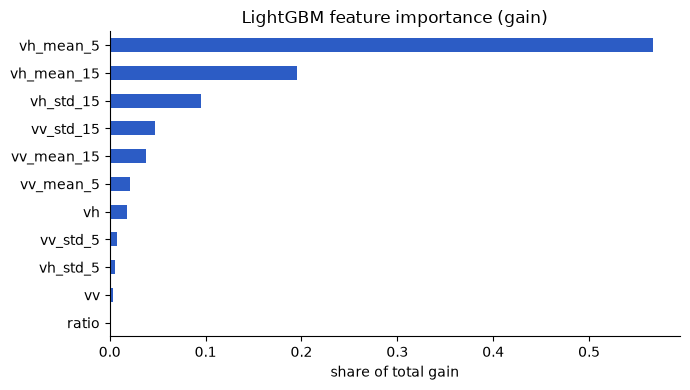

{'local mean': 0.821, 'local std': 0.156, 'single pixel': 0.023}
top feature: vh_mean_5 0.567


In [29]:
gain = pd.Series(lgbm.booster_.feature_importance("gain"), index=lgbm.booster_.feature_name())
gain = (gain / gain.sum()).sort_values()
ax = gain.plot.barh(figsize=(7, 4), color="#2c5cc5")
ax.set_xlabel("share of total gain"); ax.set_title("LightGBM feature importance (gain)")
plt.tight_layout(); plt.show()
kind = gain.index.map(lambda f: "local mean" if "_mean_" in f else "local std" if "_std_" in f else "single pixel")
print(gain.groupby(kind).sum().sort_values(ascending=False).round(3).to_dict())
print("top feature:", gain.idxmax(), round(gain.max(), 3))

**What to notice:** the four neighbourhood **means** carry most of the gain (about 82%), with `vh_mean_5`
alone over half; the four local standard deviations about 16%; the three single-pixel values only about 2%.
The model leans on the speckle-free neighbourhood averages from Part 3.4 and hardly uses a pixel's own
noisy value. VH matters more than VV here, even though the simple threshold uses VV.

### 7.4 Predict one chip

`lgbm.predict_proba(features)` gives, for every row, the probability of "not water" and of "water".
`pixel_model.predictor(model, threshold=0.5)` wraps this into a predictor: water where the probability is at
least 0.5 and the radar is not NaN.

LightGBM on India_900498_S1Hand.tif: IoU 0.712  precision 0.927  recall 0.754


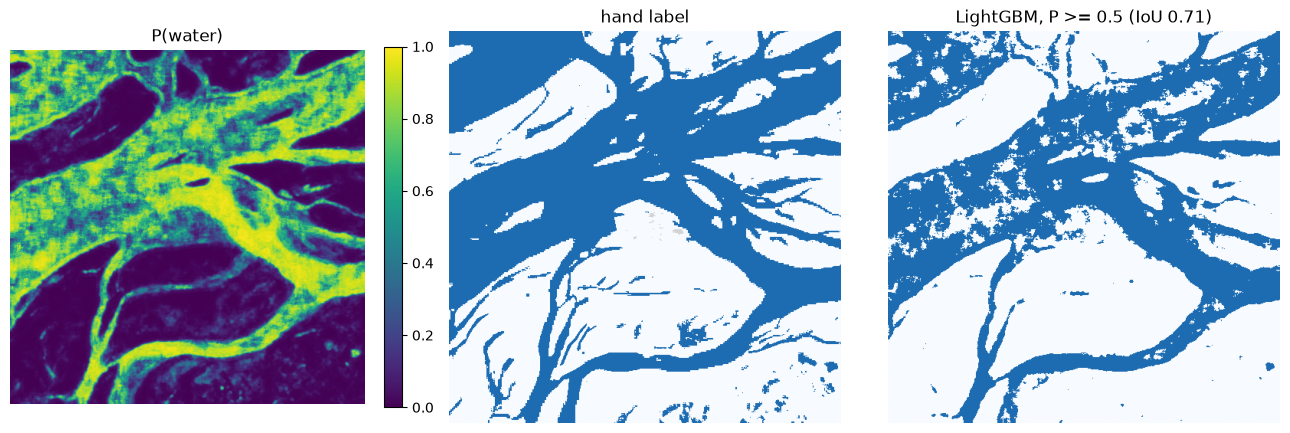

In [30]:
prob = lgbm.predict_proba(pixel_model.pixel_features(chip))[:, 1].reshape(chip.label.shape)
lgbm_predict = pixel_model.predictor(lgbm)
lgbm_mask = lgbm_predict(chip)
c = evaluation.Confusion().add(lgbm_mask, chip.label)
print(f"LightGBM on {CHIP_NAME}: IoU {c.iou:.3f}  precision {c.precision:.3f}  recall {c.recall:.3f}")

fig, axes = plt.subplots(1, 3, figsize=(13, 4.4))
im = axes[0].imshow(prob, cmap="viridis", vmin=0, vmax=1); axes[0].set_title("P(water)"); axes[0].axis("off")
fig.colorbar(im, ax=axes[0], fraction=0.046)
show_mask(axes[1], chip.label == 1, "hand label", chip.label)
show_mask(axes[2], lgbm_mask, f"LightGBM, P >= 0.5 (IoU {c.iou:.2f})")
plt.tight_layout(); plt.show()

### 7.5 Score the three non-neural methods on the official test split

`evaluation.evaluate` loads each of the 90 test chips once and runs all three predictors on it. Because
everything uses fixed seeds, the result should match the full run in `results/benchmark.json` (written by
`scripts/train.py`). *(slow, about 70 s: LightGBM predicts 262,144 pixels per chip)*

In [31]:
t0 = time.time()
test_names = data.split_names("test")
predictors = {"VV threshold": vv_predict, "Authors' Otsu": otsu_predict, "LightGBM (radar + texture)": lgbm_predict}
test_eval = evaluation.evaluate(predictors, test_names)
print(f"scored {len(test_names)} test chips in {time.time() - t0:.0f} s")

rows = {}
for method, e in test_eval.items():
    d = e.pooled.as_dict()
    rows[method] = {"IoU (this notebook)": d["IoU"], "precision": d["precision"], "recall": d["recall"],
                    "IoU (results/benchmark.json)": bench["splits"]["test"][method]["pooled"]["IoU"]}
pd.DataFrame(rows).T

scored 90 test chips in 61 s


,IoU (this notebook),precision,recall,IoU (results/benchmark.json)
VV threshold,0.464,0.771,0.538,0.464
Authors' Otsu,0.554,0.682,0.748,0.554
LightGBM (radar + texture),0.637,0.887,0.693,0.637


**What to notice:** the notebook reproduces the full-run test IoUs. Each step up in complexity helps:
the per-scene Otsu beats one global threshold, and LightGBM, with its neighbourhood features, beats both.

### 7.6 The full official benchmark, all five methods

Here is the complete table from `results/benchmark.json`, including the two U-Nets (trained in the full run;
see notebook 02). **valid** and **test** are familiar floods; **bolivia** is the one flood the official split
never trains on.

In [32]:
METHODS = ["VV threshold", "Authors' Otsu", "LightGBM (radar + texture)", "U-Net (radar)", "U-Net (radar + optical)"]
official = pd.DataFrame({split: {m: bench["splits"][split][m]["pooled"]["IoU"] for m in METHODS}
                         for split in ("valid", "test", "bolivia")})
official

,valid,test,bolivia
VV threshold,0.465,0.464,0.441
Authors' Otsu,0.507,0.554,0.718
LightGBM (radar + texture),0.600,0.637,0.405
U-Net (radar),0.638,0.672,0.597
U-Net (radar + optical),0.815,0.830,0.811


**What to notice:** on the familiar test chips the order is clean, from 0.46 (VV threshold) to 0.83 (U-Net
radar + optical). But look at the **bolivia** column, the only unseen flood: LightGBM drops to 0.40, below the
simple VV threshold (0.44), and the no-training Otsu maps (0.72) beat every radar-only learned method. One
flood is a small sample, which is exactly why Part 8 tests on every flood.

## 8. Two kinds of test: the official split and leave-one-event-out

### 8.1 Why the official test is too kind

In the official split, the test chips come from the same 10 floods as the training chips: same dates, same
landscapes, same radar conditions. A method can learn *"in this flood, water is about −17 dB"* and be
rewarded for it on the test. That is like revising with the exam's sister questions.

**Leave-one-event-out** (also called leave-one-group-out cross-validation) asks the real question. For each
of the 11 floods in turn: train on all chips of the other 10 floods and score on every chip of the held-out
flood. Each of these 11 rounds is a **fold**. `scripts/cross_event.py` defines them in `folds()`:

In [33]:
import cross_event   # scripts/cross_event.py; importing it runs nothing heavy (and does not import torch)

fold_list = cross_event.folds()
pd.DataFrame([{"held-out flood": event, "training chips": len(tr), "held-out chips": len(te)}
              for event, tr, te in fold_list]).set_index("held-out flood")

,training chips,held-out chips
held-out flood,,
Bolivia,431,15
Ghana,393,53
India,378,68
Mekong,416,30
Nigeria,428,18
Pakistan,418,28
Paraguay,379,67
Somalia,420,26
Spain,416,30


In the full run, `cross_event.py` does, for each fold: fit a VV threshold on the training chips, train
LightGBM on them, train both U-Nets (choosing their best epoch on 10% of the *training* chips, never the
held-out flood), and score all five methods on the held-out chips. It also records each flood's
**oracle threshold**: the VV cut-off that would be best for that flood *using its own labels*. That is
impossible in real life, but it shows where the right cut-off actually is. The full run takes hours (22 U-Net
trainings), so here we reproduce parts of it cheaply.

### 8.2 The VV threshold for all 11 folds, cheaply

Calling `fit_threshold` 22 times (a learned and an oracle threshold per fold) would re-read about 400 chips
each time. Instead, we read every chip **once** and, for each event, count how many labelled pixels (and how
many water pixels) are darker than each candidate. Counts can be added, so a fold's counts are the sum over
its 10 training events. From the counts, IoU follows exactly as in `fit_threshold`:
`IoU(t) = TP / (k + total_water − TP)`. Same maths, same candidates, same tie-breaking (first best wins), so
the results must equal `fit_threshold`'s. *(slow, about 30 s: reads all 446 chips)*

While reading, we also keep a small random sample of pixels per event for Part 9.

In [34]:
t0 = time.time()
candidates = np.arange(-25.0, -10.0, 0.25)          # the same default candidates as fit_threshold
below_all = {e: np.zeros(len(candidates)) for e in config.EVENTS}    # labelled pixels with VV < t
below_water = {e: np.zeros(len(candidates)) for e in config.EVENTS}  # water pixels with VV < t
total_water = dict.fromkeys(config.EVENTS, 0)
event_sample = {e: {"vv": [], "water": []} for e in config.EVENTS}
rng = np.random.default_rng(config.RANDOM_SEED)
for name in names:
    c = data.load_chip(name)
    ok = c.label != config.NODATA_LABEL
    v, w = c.s1[0][ok], c.label[ok] == 1
    e = c.event
    below_all[e] += np.searchsorted(np.sort(v), candidates)        # side='left' -> counts VV < t
    below_water[e] += np.searchsorted(np.sort(v[w]), candidates)
    total_water[e] += int(w.sum())
    take = rng.choice(len(v), size=min(2000, len(v)), replace=False)
    event_sample[e]["vv"].append(v[take]); event_sample[e]["water"].append(w[take])
print(f"read {len(names)} chips in {time.time() - t0:.0f} s")


def best_threshold(events):
    k = sum(below_all[e] for e in events)
    tp = sum(below_water[e] for e in events)
    tw = sum(total_water[e] for e in events)
    iou = tp / np.maximum(k + tw - tp, 1)
    return float(candidates[int(np.argmax(iou))])


cross = json.loads((RESULTS / "cross_event.json").read_text())
thresholds = pd.DataFrame({
    "learned from the other 10": {e: best_threshold([o for o in config.EVENTS if o != e]) for e in config.EVENTS},
    "full run: learned": cross["fold_threshold_db"],
    "oracle (own labels)": {e: best_threshold([e]) for e in config.EVENTS},
    "full run: oracle": cross["oracle_threshold_db"],
})
print("all equal to the full run:",
      bool((thresholds.iloc[:, 0] == thresholds.iloc[:, 1]).all() and (thresholds.iloc[:, 2] == thresholds.iloc[:, 3]).all()))
thresholds

read 446 chips in 7 s
all equal to the full run: True


,learned from the other 10,full run: learned,oracle (own labels),full run: oracle
Bolivia,-16.75,-16.75,-13.50,-13.50
Ghana,-16.75,-16.75,-14.50,-14.50
India,-16.75,-16.75,-14.75,-14.75
Mekong,-16.50,-16.50,-14.00,-14.00
Nigeria,-16.75,-16.75,-14.50,-14.50
Pakistan,-16.50,-16.50,-16.50,-16.50
Paraguay,-16.50,-16.50,-17.50,-17.50
Somalia,-16.25,-16.25,-17.50,-17.50
Spain,-16.50,-16.50,-17.25,-17.25
Sri-Lanka,-16.75,-16.75,-12.50,-12.50


A spot check with the project's own function for one flood (its oracle threshold needs only its own 42
chips, so it is quick):

In [35]:
sri_lanka = [n for n in names if data.event_of(n) == "Sri-Lanka"]
print("fit_threshold on Sri-Lanka's own chips:", evaluation.fit_threshold(sri_lanka), "dB")

fit_threshold on Sri-Lanka's own chips: -12.5 dB


**What to notice:** the threshold learned from the other ten floods is nearly the same number in every fold
(−16.0 to −16.75 dB), but each flood's own best threshold ranges from −18.25 dB (USA) to −12.5 dB
(Sri Lanka). Part 9.1 draws this.

### 8.3 One full fold for LightGBM: hold out Sri Lanka

Now the real procedure for one fold, exactly as `cross_event.py` runs it: train LightGBM on the 404 chips of
the other ten floods, then score the VV threshold (learned from the same ten floods), the authors' Otsu maps,
and LightGBM on Sri Lanka's 42 chips. *(slow, about 60 s)*

In [36]:
t0 = time.time()
event, fold_train, fold_test = next(f for f in fold_list if f[0] == "Sri-Lanka")
fold_lgbm = pixel_model.train(fold_train)
fold_predictors = {
    "VV threshold": evaluation.threshold_predictor(thresholds.loc[event, "learned from the other 10"]),
    "Authors' Otsu": evaluation.authors_otsu_predictor(),
    "LightGBM (radar + texture)": pixel_model.predictor(fold_lgbm),
}
fold_eval = evaluation.evaluate(fold_predictors, fold_test)
print(f"fold '{event}': trained on {len(fold_train)} chips, scored {len(fold_test)} chips in {time.time() - t0:.0f} s")
pd.DataFrame({m: {"IoU (this notebook)": e.pooled.iou,
                  "IoU (results/cross_event.json)": evaluation.Confusion(
                      **{k: cross["events"][event][m][k] for k in ("tp", "fp", "fn", "tn")}).iou}
              for m, e in fold_eval.items()}).T

fold 'Sri-Lanka': trained on 404 chips, scored 42 chips in 70 s


,IoU (this notebook),IoU (results/cross_event.json)
VV threshold,0.162,0.162
Authors' Otsu,0.649,0.649
LightGBM (radar + texture),0.586,0.586


**What to notice:** the notebook reproduces the full run's numbers for this fold. In Sri Lanka, water is
unusually bright in radar, so the learned VV threshold (−16.75 dB, much darker than Sri Lanka's best
−12.5 dB) misses most of it: IoU 0.16. Otsu, which picks a cut-off per scene, copes far better (0.65).
LightGBM, also trained only on other floods, reaches 0.59: much better than the threshold, still below Otsu.

### 8.4 The full leave-one-event-out results

`results/cross_event.json` stores, for every held-out flood and every method, the four confusion counts.
We turn them into IoUs per flood, and **pool** over all 11 floods (sum the counts, then one IoU, as in
Part 4.4). Floods are sorted from hardest to easiest for radar (by VV AUC, explained in Part 9.2).

In [37]:
def iou_of(counts):
    return counts["tp"] / max(counts["tp"] + counts["fp"] + counts["fn"], 1)


separability = pd.read_csv(RESULTS / "event_separability.csv", index_col="event")
flood_order = separability["vv_auc"].sort_values().index
held_out = pd.DataFrame({e: {m: iou_of(cross["events"][e][m]) for m in METHODS} for e in config.EVENTS}).T
held_out = held_out.loc[flood_order]
pooled_new = pd.Series({m: iou_of({k: sum(cross["events"][e][m][k] for e in config.EVENTS)
                                   for k in ("tp", "fp", "fn")}) for m in METHODS})
grid_table = pd.concat([held_out, pooled_new.to_frame("Pooled (all 11)").T])
grid_table.style.format("{:.2f}").background_gradient(cmap="RdYlGn", vmin=0, vmax=1, axis=None)

,VV threshold,Authors' Otsu,LightGBM (radar + texture),U-Net (radar),U-Net (radar + optical)
Somalia,0.15,0.15,0.22,0.27,0.70
Paraguay,0.43,0.45,0.55,0.53,0.60
Pakistan,0.24,0.15,0.30,0.32,0.65
Sri-Lanka,0.16,0.65,0.59,0.68,0.85
Ghana,0.35,0.41,0.39,0.49,0.68
USA,0.29,0.51,0.51,0.50,0.78
Nigeria,0.55,0.64,0.65,0.76,0.89
India,0.47,0.53,0.51,0.53,0.71
Spain,0.63,0.67,0.72,0.56,0.85
Bolivia,0.44,0.72,0.43,0.68,0.81


Side by side with the official test split from Part 7.6: familiar floods vs new floods, and which method wins
each held-out flood.

In [38]:
compare = pd.DataFrame({"familiar floods (official test)": official["test"],
                        "new floods (pooled, leave-one-event-out)": pooled_new})
compare["change"] = compare.iloc[:, 1] - compare.iloc[:, 0]
print("best method per held-out flood:", held_out.idxmax(axis=1).value_counts().to_dict())
compare

best method per held-out flood: {'U-Net (radar + optical)': 11}


,familiar floods (official test),"new floods (pooled, leave-one-event-out)",change
VV threshold,0.464,0.434,-0.030
Authors' Otsu,0.554,0.495,-0.059
LightGBM (radar + texture),0.637,0.566,-0.071
U-Net (radar),0.672,0.587,-0.085
U-Net (radar + optical),0.830,0.775,-0.055


**What to notice**

- Every method scores lower on new floods than on familiar ones. The pooled new-flood IoUs are 0.43 (VV
  threshold), 0.50 (Otsu), 0.57 (LightGBM), 0.59 (U-Net radar) and 0.78 (U-Net radar + optical).
- The U-Net (radar + optical) is the best method on all 11 held-out floods.
- The colours change more *across* floods (down the columns) than *between* methods (along a row) for the
  four radar-only methods. Part 9 explains why.
- Otsu's maps were not trained at all, yet its score also changes (0.55 → 0.50): the two rows score
  different chips (90 test chips vs all 446), so the "change" for a method without training says how much
  harder the full set of floods is, not how much it lost by not having seen them.

## 9. Why floods differ

### 9.1 The right threshold moves; a learned one cannot

Each flood gets a vertical line: the dot is its oracle threshold (best for that flood, using its own labels),
the cross is the threshold learned from the other ten floods.

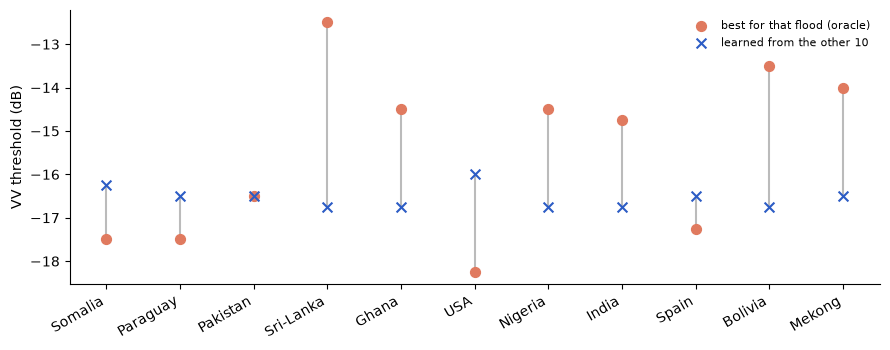

oracle range: -18.25 to -12.5 dB (spread 5.75 dB); learned range: -16.75 to -16.0 dB


In [39]:
fig, ax = plt.subplots(figsize=(9, 3.6))
xpos = np.arange(len(flood_order))
oracle = thresholds.loc[flood_order, "oracle (own labels)"]
learned = thresholds.loc[flood_order, "learned from the other 10"]
ax.vlines(xpos, oracle, learned, color="#bbb", zorder=1)
ax.scatter(xpos, oracle, color="#e07a5f", s=50, zorder=3, label="best for that flood (oracle)")
ax.scatter(xpos, learned, color="#2c5cc5", marker="x", s=50, zorder=3, label="learned from the other 10")
ax.set_xticks(xpos, flood_order, rotation=30, ha="right"); ax.set_ylabel("VV threshold (dB)")
ax.legend(frameon=False, fontsize=8); plt.tight_layout(); plt.show()
print(f"oracle range: {oracle.min()} to {oracle.max()} dB (spread {oracle.max() - oracle.min():.2f} dB); "
      f"learned range: {learned.min()} to {learned.max()} dB")

**What to notice:** the crosses form an almost flat line, the dots jump around. A threshold learned from many
floods is a compromise that fits none of them exactly. Where the gap is large (Sri Lanka, 4.25 dB), the VV
threshold collapses (IoU 0.16 there, Part 8.4). Otsu's per-scene cut-off follows the scene, which is why it
wins exactly on those floods.

### 9.2 How visible is water to radar? `results/event_separability.csv`

`analysis.event_separability()` (run by `scripts/analyze.py`) samples up to 20,000 labelled pixels per chip
and summarises each flood:

| Column | Meaning |
|---|---|
| `chips` | chips with at least one labelled pixel |
| `water_share` | water pixels / labelled pixels |
| `vv_water_median_db`, `vv_land_median_db` | typical VV of water and of land |
| `contrast_db` | land median − water median: how much darker water is |
| `vv_auc` | how well VV alone ranks water below land (see below) |

**AUC** (area under the ROC curve) has a simple meaning here: pick one random water pixel and one random
land pixel; AUC is the probability that the water pixel is darker. 1.0 = some threshold separates them
perfectly; 0.5 = a coin toss. It does not depend on any particular threshold. A by-hand check for Sri Lanka
with the sample kept in Part 8.2:

In [40]:
from sklearn.metrics import roc_auc_score

s_vv = np.concatenate(event_sample["Sri-Lanka"]["vv"])
s_w = np.concatenate(event_sample["Sri-Lanka"]["water"])
rng = np.random.default_rng(0)
pairs = 200_000
water_px = rng.choice(s_vv[s_w], pairs)
land_px = rng.choice(s_vv[~s_w], pairs)
print(f"P(random water pixel darker than random land pixel): {np.mean(water_px < land_px):.3f}  (by hand)")
print(f"roc_auc_score on the same sample:                   {roc_auc_score(s_w, -s_vv):.3f}")
print(f"results/event_separability.csv (larger sample):      {separability.loc['Sri-Lanka', 'vv_auc']:.3f}")

P(random water pixel darker than random land pixel): 0.810  (by hand)
roc_auc_score on the same sample:                   0.810
results/event_separability.csv (larger sample):      0.813


The three agree closely (the CSV used a larger sample). Here is the whole table, from the hardest flood for
radar to the easiest:

In [41]:
separability.sort_values("vv_auc")

,chips,water_share,vv_water_median_db,vv_land_median_db,vv_auc,contrast_db
event,,,,,,
Somalia,26,0.065,-14.474,-11.873,0.702,2.601
Paraguay,66,0.081,-16.316,-9.601,0.762,6.715
Pakistan,28,0.075,-15.784,-9.695,0.773,6.089
Sri-Lanka,42,0.118,-12.579,-8.676,0.813,3.904
Ghana,48,0.063,-15.204,-9.138,0.864,6.065
USA,69,0.046,-18.698,-10.759,0.869,7.939
Nigeria,18,0.236,-18.089,-9.848,0.880,8.241
India,68,0.124,-17.618,-8.343,0.889,9.275
Spain,30,0.132,-21.958,-10.113,0.926,11.845


**What to notice:** in Somalia water is only about 2.6 dB darker than land (AUC 0.70, not far above a coin
toss); in the Mekong it is about 12 dB darker (AUC 0.97). The water share also varies, from under 5% (USA)
to about a quarter of the pixels (Nigeria, Mekong).

### 9.3 The flood matters more than the method (for radar)

Plot each method's held-out IoU against the flood's VV AUC:

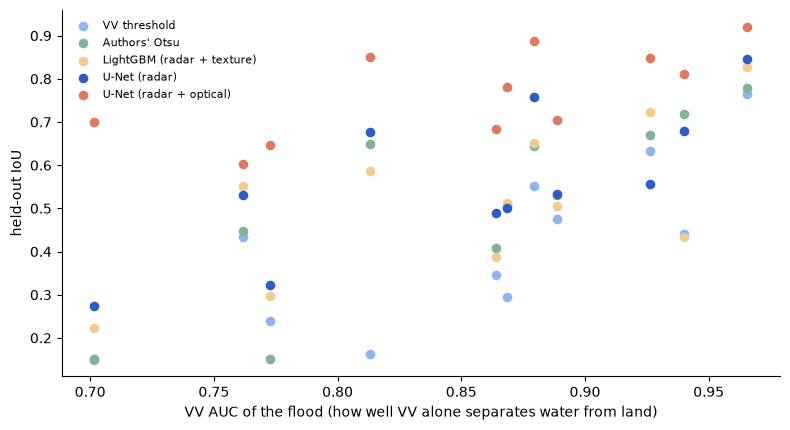

correlation of held-out IoU with VV AUC: {'VV threshold': np.float64(0.77), "Authors' Otsu": np.float64(0.84), 'LightGBM (radar + texture)': np.float64(0.68), 'U-Net (radar)': np.float64(0.75), 'U-Net (radar + optical)': np.float64(0.68)}
radar-only methods: best-to-worst flood, averaged over methods:  0.61
radar-only methods: best-to-worst method, averaged over floods:  0.19


In [42]:
COLORS = dict(zip(METHODS, ["#8fb4f2", "#81b29a", "#f2cc8f", "#2c5cc5", "#e07a5f"]))
fig, ax = plt.subplots(figsize=(8, 4.4))
for m in METHODS:
    ax.scatter(separability.loc[held_out.index, "vv_auc"], held_out[m], s=35, color=COLORS[m], label=m)
ax.set_xlabel("VV AUC of the flood (how well VV alone separates water from land)")
ax.set_ylabel("held-out IoU"); ax.legend(frameon=False, fontsize=8); plt.tight_layout(); plt.show()

corr = {m: held_out[m].corr(separability.loc[held_out.index, "vv_auc"]) for m in METHODS}
print("correlation of held-out IoU with VV AUC:", {m: round(v, 2) for m, v in corr.items()})

radar_only = METHODS[:4]
across_floods = (held_out[radar_only].max() - held_out[radar_only].min()).mean()
across_methods = (held_out[radar_only].max(axis=1) - held_out[radar_only].min(axis=1)).mean()
print(f"radar-only methods: best-to-worst flood, averaged over methods:  {across_floods:.2f}")
print(f"radar-only methods: best-to-worst method, averaged over floods:  {across_methods:.2f}")

**What to notice:** points rise from bottom-left to top-right for every method (**correlation**: a number
from −1 to 1 measuring how closely two quantities move together; here 0.68 to 0.84). For the four radar-only
methods, a method's IoU moves by about 0.61 on average from its best to its worst flood, while the methods
differ by only about 0.19 on the same flood. Knowing *which flood* you map predicts the quality better than
knowing *which radar method* you used. The radar + optical U-Net breaks this pattern most: optical data does
not depend on radar contrast.

### 9.4 Where is water missed? `results/error_anatomy_<method>.json`

`analysis.error_anatomy(slug)` (run by `scripts/analyze.py`) takes a method's held-out predictions (Part 10)
and splits its errors two ways:

1. **By water type**: recall on **permanent water** (pixels the JRC map marks as normal rivers and lakes) vs
   **new floodwater** (water everywhere else).
2. **By vegetation**: **NDVI** (normalised difference vegetation index, `(NIR − red) / (NIR + red)`,
   `data.ndvi`) measures plant cover; higher = greener. It is computed from the optical image, so only
   **clear-sky** pixels are used: blue reflectance below 0.15 (`analysis.CLEAR_SKY_MAX_BLUE`), because clouds
   are bright in blue.

The file names use a **slug** of each method name, made by `cross_event.method_slug`:

In [43]:
SLUGS = {m: cross_event.method_slug(m) for m in METHODS}
anatomy = {m: json.loads((RESULTS / f"error_anatomy_{s}.json").read_text()) for m, s in SLUGS.items()}
print(SLUGS)
pd.DataFrame({m: {r["water type"]: r["recall"] for r in a["by_water_type"]} for m, a in anatomy.items()}).T

{'VV threshold': 'vv_threshold', "Authors' Otsu": 'authors_otsu', 'LightGBM (radar + texture)': 'lightgbm_radar_plus_texture', 'U-Net (radar)': 'u_net_radar', 'U-Net (radar + optical)': 'u_net_radar_plus_optical'}


,new floodwater,permanent water
VV threshold,0.446,0.753
Authors' Otsu,0.604,0.989
LightGBM (radar + texture),0.520,0.941
U-Net (radar),0.620,0.907
U-Net (radar + optical),0.810,0.995


The vegetation breakdown for the best model, with the VV threshold's recall added for comparison. Columns:
clear-sky labelled pixels in each NDVI band, the share of them that is water, recall, and the
**false-alarm rate** (share of non-water pixels called water).

In [44]:
best = "U-Net (radar + optical)"
veg = pd.DataFrame(anatomy[best]["by_vegetation"]).set_index("ndvi")
veg_vv = pd.DataFrame(anatomy["VV threshold"]["by_vegetation"]).set_index("ndvi")
veg.assign(**{"recall, VV threshold": veg_vv["recall"]})

,clear-sky pixels,water share,recall,false-alarm rate,"recall, VV threshold"
ndvi,,,,,
bare / water (< 0.2),11588227,0.639,0.912,8.451e-02,0.552
sparse (0.2-0.4),18090956,0.019,0.243,2.831e-02,0.078
moderate (0.4-0.6),28424585,0.004,0.054,2.052e-03,0.039
dense (> 0.6),24687506,0.002,0.013,1.603e-04,0.033


**What to notice**

- Every method finds most permanent water (75% to 99%) but much less new floodwater (45% to 81%). Rivers
  and lakes are deep, open and calm; floodwater is often shallow, among crops or trees, or wind-roughened.
- Recall collapses as vegetation increases: the best model finds about 91% of the water on bare ground
  but about 24% where plants are sparse and almost none under dense plants. Water under a plant canopy is
  hidden from both radar and optical sensors.
- But check the `water share` column: under 2% of vegetated clear-sky pixels are water, so these recalls
  rest on small amounts of water.

The third table in each file breaks the water-type recall down per flood:

In [45]:
per_event = pd.DataFrame(anatomy[best]["by_event_and_water_type"])
per_event.pivot(index="event", columns="water type", values="recall").loc[flood_order]

water type,new floodwater,permanent water
event,,
Somalia,0.879,NaN
Paraguay,0.531,0.992
Pakistan,0.785,0.958
Sri-Lanka,0.642,0.996
Ghana,0.702,0.967
USA,0.747,0.998
Nigeria,0.969,1.000
India,0.789,0.996
Spain,0.910,0.999


## 10. Looking at the predictions

`scripts/cross_event.py` saved every method's **held-out** map of every chip (each chip predicted by a model
that never saw its flood) to `results/predictions/<slug>.npz`. To keep the files small, each 512 × 512
True/False map is **bit-packed** with `np.packbits` (8 pixels per byte: 262,144 pixels → 32,768 bytes).
`analysis.load_predictions(slug)` unpacks all 446 chips of one method into a dict `{chip name: mask}`:

In [46]:
vv_maps = analysis.load_predictions(SLUGS["VV threshold"])
print(len(vv_maps), "chips; one map:", vv_maps[CHIP_NAME].shape, vv_maps[CHIP_NAME].dtype)
with np.load(RESULTS / "predictions" / f"{SLUGS['VV threshold']}.npz") as packed:
    print("stored (packed) size of one map:", packed[CHIP_NAME].shape, packed[CHIP_NAME].dtype)
del vv_maps   # 446 unpacked maps take ~117 MB; we only need one chip at a time

446 chips; one map: (512, 512) bool
stored (packed) size of one map: (32768,) uint8


To look at one chip we only need to unpack that chip. This helper does the same unpacking as
`analysis.load_predictions`, for one name:

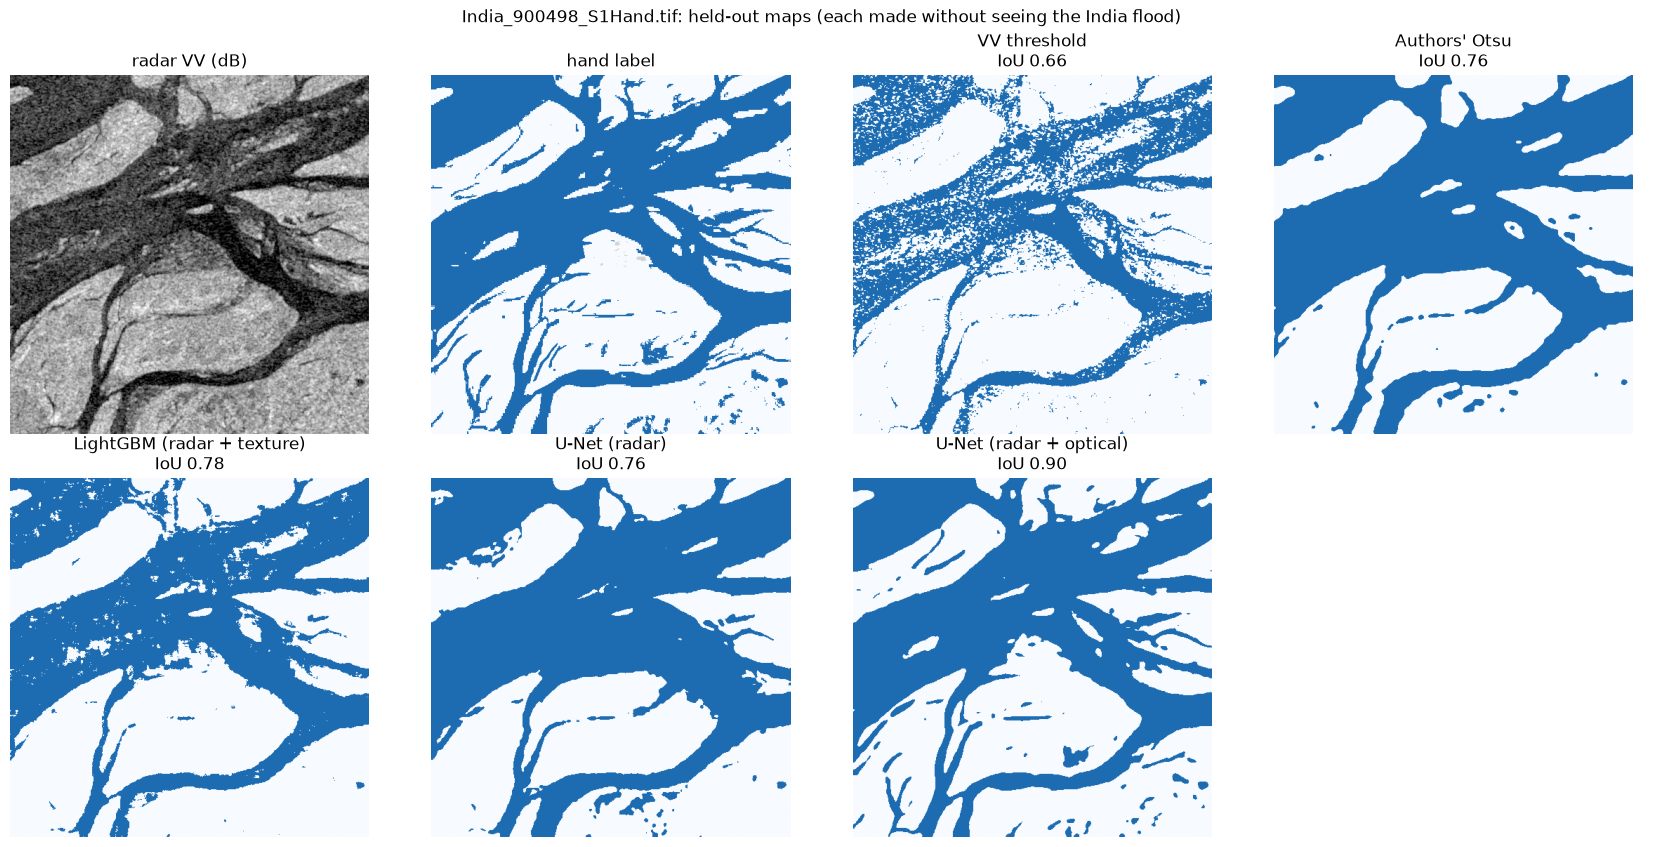

held-out IoU on this chip: {'VV threshold': 0.66, "Authors' Otsu": 0.761, 'LightGBM (radar + texture)': 0.782, 'U-Net (radar)': 0.762, 'U-Net (radar + optical)': 0.904}


In [47]:
def held_out_map(method, name):
    with np.load(RESULTS / "predictions" / f"{SLUGS[method]}.npz") as packed:
        bits = np.unpackbits(packed[name])[: config.CHIP_SIZE ** 2]
    return bits.reshape(config.CHIP_SIZE, config.CHIP_SIZE).astype(bool)


def compare_methods(name):
    c = data.load_chip(name)
    fig, axes = plt.subplots(2, 4, figsize=(17, 8.6))
    show_vv(axes[0, 0], c)
    show_mask(axes[0, 1], c.label == 1, "hand label", c.label)
    scores = {}
    for ax, m in zip(axes.ravel()[2:], METHODS):
        conf = evaluation.Confusion().add(held_out_map(m, name), c.label)
        scores[m] = round(conf.iou, 3)
        show_mask(ax, held_out_map(m, name), f"{m}\nIoU {conf.iou:.2f}")
    axes[1, 3].axis("off")
    fig.suptitle(f"{name}: held-out maps (each made without seeing the {c.event} flood)")
    plt.tight_layout(); plt.show()
    print("held-out IoU on this chip:", scores)


compare_methods(CHIP_NAME)

**What to notice:** these maps come from leave-one-event-out models (trained without any India chips), so
they differ from the official-split maps in Parts 5 and 7 (for the VV threshold the learned cut-off happens
to be the same, −16.75 dB, so its map and IoU of 0.66 are identical). The VV threshold scatters dots along
the river; Otsu (0.76), LightGBM (0.78) and the radar U-Net (0.76) clean that up in different ways; the
radar + optical U-Net draws shapes closest to the label (0.90).

The six pixels from Part 2.7, now with each method's held-out answer:

In [48]:
answers = pixel_table[["VV (dB)", "VH (dB)", "NDWI", "hand label"]].copy()
for m in METHODS:
    pred = held_out_map(m, CHIP_NAME)
    answers[m] = ["water" if pred[r, c] else "not water" for r, c in PIXELS]
answers

,VV (dB),VH (dB),NDWI,hand label,VV threshold,Authors' Otsu,LightGBM (radar + texture),U-Net (radar),U-Net (radar + optical)
"row, col",,,,,,,,,
"(177, 87)",-22.299,-25.012,0.176,water,water,water,water,water,water
"(263, 395)",-15.536,-35.442,0.217,water,not water,water,water,water,water
"(356, 419)",-16.985,-37.104,0.152,water,water,water,water,water,water
"(104, 328)",-13.184,-23.702,0.132,not water,not water,water,water,water,water
"(19, 16)",-5.415,-15.115,-0.369,not water,not water,not water,not water,not water,not water
"(455, 232)",-7.922,-18.980,-0.055,not water,not water,not water,not water,not water,not water


**What to notice:** pixel (263, 395) is real floodwater at about −15.5 dB, brighter than the −16.75 dB
cut-off learned from the other floods, so the VV threshold calls it dry; every other method calls it water
(its very dark VH and positive NDWI give it away). No method is perfect: (104, 328) is dry land that every
method except the VV threshold calls water.

An **error map** shows *where* a method goes wrong: green = found water (TP), red = false alarm (FP),
orange = missed water (FN). Here for chip Sri-Lanka_321316, from the flood where the learned threshold
failed most. It is a chip with plenty of both water (about 37%) and land, so all three outcomes are visible:

labelled water on this chip: 37.0%
VV threshold               IoU 0.05  recall 0.06  precision 0.46
Authors' Otsu              IoU 0.77  recall 0.91  precision 0.84
U-Net (radar + optical)    IoU 0.92  recall 0.94  precision 0.98


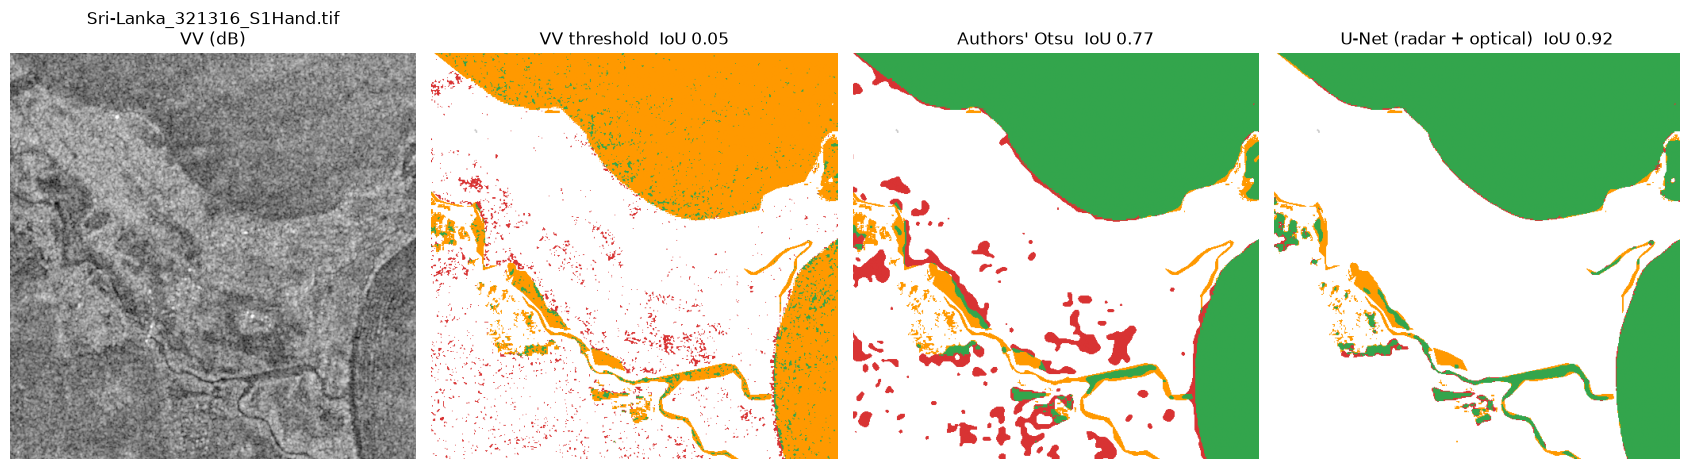

median VV of water on this chip: -12.8 dB (learned threshold for the Sri-Lanka fold: -16.75 dB)


In [49]:
def error_map(ax, predicted, label, title):
    rgb = np.ones(label.shape + (3,))
    t, ok = label == 1, label != config.NODATA_LABEL
    rgb[ok & predicted & t] = (0.2, 0.65, 0.3)      # TP green
    rgb[ok & predicted & ~t] = (0.85, 0.2, 0.2)     # FP red
    rgb[ok & ~predicted & t] = (1.0, 0.6, 0.0)      # FN orange
    rgb[~ok] = (0.8, 0.8, 0.8)                      # no data grey
    ax.imshow(rgb); ax.set_title(title); ax.axis("off")


sl_name = "Sri-Lanka_321316_S1Hand.tif"
sl = data.load_chip(sl_name)
print(f"labelled water on this chip: {(sl.label == 1).sum() / (sl.label != config.NODATA_LABEL).sum():.1%}")
fig, axes = plt.subplots(1, 4, figsize=(17, 4.6))
show_vv(axes[0], sl, f"{sl_name}\nVV (dB)")
for ax, m in zip(axes[1:], ["VV threshold", "Authors' Otsu", "U-Net (radar + optical)"]):
    pred = held_out_map(m, sl_name)
    conf = evaluation.Confusion().add(pred, sl.label)
    error_map(ax, pred, sl.label, f"{m}  IoU {conf.iou:.2f}")
    print(f"{m:<26} IoU {conf.iou:.2f}  recall {conf.recall:.2f}  precision {conf.precision:.2f}")
plt.tight_layout(); plt.show()
w = sl.label == 1
print(f"median VV of water on this chip: {np.median(sl.s1[0][w]):.1f} dB "
      f"(learned threshold for the Sri-Lanka fold: {thresholds.loc['Sri-Lanka', 'learned from the other 10']} dB)")

**What to notice:** the typical water pixel on this chip is about −12.8 dB, roughly 4 dB brighter than the
cut-off learned from the other floods, so the VV threshold leaves almost all of it orange (missed; IoU about
0.05). Otsu, choosing a cut-off for this scene, recovers most of it (about 0.77), and the radar + optical
U-Net more still (about 0.92). This one chip is the Sri Lanka row of the table in Part 8.4 in miniature.

## 11. Recap, reproducing everything, and exercises

### 11.1 Where everything lives

| Step | Function | File |
|---|---|---|
| list chips, splits, events | `split_names`, `all_names`, `event_of` | `data.py` |
| load one chip | `load_chip` → `Chip` | `data.py` |
| model inputs (U-Net) | `raw_channels`, `model_input`, `ndwi`, `ndvi` | `data.py` |
| constants (clips, means, stds, events, seed) | module constants | `config.py` |
| scoring | `Confusion`, `Evaluation`, `evaluate` | `evaluation.py` |
| Method 1, VV threshold | `fit_threshold`, `threshold_predictor` | `evaluation.py` |
| Method 2, authors' Otsu | `authors_otsu_predictor` (and `otsu_water` for illustration) | `evaluation.py` |
| Method 3, LightGBM | `pixel_features`, `training_table`, `train`, `predictor` | `pixel_model.py` |
| Methods 4 and 5, U-Nets | `build_unet`, `BceDiceLoss`, `train_unet`, `predict_probability`, `unet_predictor` | `unet.py` (notebook 02) |
| folds of leave-one-event-out | `folds`, `method_slug` | `scripts/cross_event.py` |
| separability, error anatomy | `event_separability`, `error_anatomy`, `load_predictions` | `analysis.py` |

### 11.2 Reproducing the full run

From the project root, with the virtual environment active (see the README for times):

```bash
python scripts/download_data.py   # the data (~2 GB)
python scripts/train.py           # official split, all five methods -> models/, results/benchmark.json
python scripts/cross_event.py     # leave-one-event-out, 11 floods -> results/cross_event.json, results/predictions/
python scripts/analyze.py         # -> results/event_separability.csv, results/error_anatomy_*.json
pytest tests/                     # unit tests on synthetic data
```

These scripts **overwrite** the files in `results/` (and write models to `models/`). Each script runs the
LightGBM part and the PyTorch part in separate processes (`subprocess.run`), the same macOS rule as the two
notebooks.

### 11.3 Exercises

Try these in new cells (they only change things in memory):

1. **A different chip.** Set `CHIP_NAME` to another chip (for example from `chips.query("event == 'Somalia'")`)
   and re-run Parts 2, 5 and 10. How does Somalia's VV histogram differ from India's?
2. **Precision vs recall.** Make `pixel_model.predictor(lgbm, threshold=0.3)` and `threshold=0.7` and score
   them on the India chip with `evaluation.Confusion`. Which one finds more water? Which raises fewer false
   alarms? What happens to IoU?
3. **Neighbourhood size.** Set `pixel_model.WINDOWS = (3, 31)` (the functions read this module variable),
   re-train on the training chips and re-score the test split. Does a wider window help? Set it back to
   `(5, 15)` afterwards.
4. **Another held-out flood.** Change `"Sri-Lanka"` in Part 8.3 to `"Somalia"` or `"Bolivia"` and compare with
   `results/cross_event.json`.
5. **The accuracy trap on one flood.** Using `cross["events"]["USA"]["VV threshold"]`, compute the accuracy of
   "no water anywhere" for the USA flood (water share under 5%).
6. **Fewer pixels per chip.** Train with `pixel_model.train(train_names, pixels_per_chip=2_000)`. How much do
   the test IoU and the training time change?

Next: **`02_unet_walkthrough.ipynb`**, the U-Net, in its own process.

In [50]:
print(f"notebook finished in {(time.time() - NOTEBOOK_STARTED) / 60:.1f} min")
assert "torch" not in sys.modules

notebook finished in 3.2 min
